# Быстрый ручной расчёт ТВД мощностью 150 л.с. при $\pi_k^*=6$

Этот файл рассчитывает **один вручную заданный вариант** двух одноступенчатых турбин. Перебора вариантов. Автоматического поиска здесь нет.

Порядок работы:

1. измените исходные данные цикла в первом блоке;
2. измените параметры турбин в блоке **«Ручной ввод параметров»**;
3. выполните `Run All`;
4. изучите итоговые таблицы, проверки, треугольники скоростей и проточную часть.

При изменении $u/c_0$ реактивность автоматически пересчитывается по принятому полиному. Итоговые обороты определяются расчётом; заданные `N_GUESS` используются только как начальные приближения.

# Расчёт цикла двигателя

### Прототипы:
- tj100
- ТВД150 МКБ «Гранит»
- Honeywell TPE331

## 1. Импорт библиотек, исходные данные

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

#-------------------------------------------
pd.set_option('display.max_rows', None)      #чтобы было видно все строки в pandas
pd.set_option('display.max_columns', None)
# Десятичный вывод с 4 знаками после точки; точность вычислений сохраняется.
pd.set_option('display.float_format', '{:.4f}'.format)
#-------------------------------------------

# Мощность двигателя
power_hp = 150.0
HP_TO_KW = 0.73549875
power_kw = power_hp * HP_TO_KW

# Наружные условия
T_a = 288.0          # K
p_a = 101.3          # кПа
velocity = 0.0       # м/с

# Температура газа перед турбиной
T_g = 1250.0         # K

# КПД и потери
eta_k_poly = 0.86    # п кпд цбк по методичке 0.85..0.87
eta_gg_poly = 0.90   # п кпд газогенератора
eta_pt_poly = 0.90   # п кпд силовой турбины

sigma_in = 0.985
sigma_burn = 0.965
eta_burn = 0.98

eta_m_gg = 0.99
eta_m_pt = 0.99

# КПД редуктора:
eta_red = 0.98

# Отборы воздуха
g_leak = 0.005
g_cool = 0.0

# Топливо и газовые постоянные
Q_lhv = 43000.0      # кДж/кг
l0 = 14.61
T_ref = 288.0        # K
R_air = 0.287        # кДж/(кг К)
R_gas = 0.288        # кДж/(кг К)

# Сопло и выход из свободной турбины
pi_nozzle_static = 1.04
c_pt_exit = 250.0    # м/с
phi_nozzle = 0.95
beta_prop = 15.0     # Н/кВт
eta_prop = 0.82

# Настройки вариантного расчёта
n_variants = 801

KCAL_TO_KJ = 4.187

print(f"Мощность на валу: {power_hp:.0f} л.с. = {power_kw:.3f} кВт")

Мощность на валу: 150 л.с. = 110.325 кВт


## 2. Теплофизические свойства

Формулы теплоёмкостей взяты из приложения 6 методички. Для воздуха используется предел alpha → infty

**Формулы следующей ячейки: теплофизические свойства и деление пополам**

Обозначения: $T$ — К, $\alpha$ — коэффициент избытка воздуха, $a=1/\alpha$; для воздуха $a=0$. Теплоёмкости — **кДж/(кг·К)**. В коде `cp_i` — истинная, `cp_m` — средняя теплоёмкость.

Вспомогательные полиномы температуры:

$$U=2.5\cdot10^{-3}T-0.875,\qquad V=2.5\cdot10^{-5}T^2-0.0275T+6.5625,$$
$$W=1.176\cdot10^{-3}T-0.88235,\qquad Z=5.5556\cdot10^{-6}T^2-0.013056T+6.67.$$

$$c_{pi}(T,\alpha)=4.187\begin{cases}
0.0174a+0.2407+(0.0093a+0.0193)U+\left(0.002-\dfrac{0.001056a}{1-0.2a}\right)V,&T<750,\\[2mm]
0.0267a+0.26+(0.0133a+0.032)W-\left(0.00374+\dfrac{0.0094a^2}{1+10a^2}\right)Z,&T\ge750.
\end{cases}$$

$$
c_{pm}(T,\alpha)=4.187\begin{cases}
\dfrac{2.25a+1.2}{10^5}(T-70)+0.236,&T<700,\\
\dfrac{1.25a+2.2}{10^5}(T+450)+0.218,&T\ge700.
\end{cases}
$$

Функции энтальпии записаны **точно как в существующем коде**:

$$h(T,\alpha)=c_{pm}(T,\alpha)T,\qquad
\Delta h(T,\alpha)=h(T,\alpha)-h(T_{ref},\alpha).$$

`process_properties` использует приближение:

$$T_m=\frac{T_1+T_2}{2},\qquad c_p=c_{pi}(T_m,\alpha),\qquad k=\frac{c_p}{c_p-R}.$$

В `bisect` решается $F(x)=0$: $m=(l+r)/2$; если $F(l)F(m)\le0$, заменяем $r=m$, иначе $l=m$. После 80 шагов возвращается $(l+r)/2$. Это выбранный численный алгоритм, не отдельная физическая формула.

**Источник:** «цикл.pdf», приложение 6, с. 56–57; согласование свойств процесса — §2.3, с. 16. Определения `h`, `dh` и правила осреднения показаны здесь для объяснения уже имеющегося кода, без изменения его модели.


In [2]:
def cp_i(T, alpha=np.inf):
    if np.isinf(alpha):
        a = 0.0
    else:
        a = 1.0 / alpha

    if T < 750.0:
        value = ((0.0174*a + 0.2407)
                 + (0.0093*a + 0.0193)*(2.5e-3*T - 0.875)
                 + (2.0e-3 - 1.056e-3*a/(1.0 - 0.2*a))
                 * (2.5e-5*T*T - 0.0275*T + 6.5625))
    else:
        value = ((0.0267*a + 0.26)
                 + (0.0133*a + 0.032)*(1.176e-3*T - 0.88235)
                 - (0.374e-2 + 0.94e-2*a*a/(1.0 + 10*a*a))
                 * (5.5556e-6*T*T - 1.3056e-2*T + 6.67))

    return KCAL_TO_KJ * value


def cp_m(T, alpha=np.inf):
    a = 0.0 if np.isinf(alpha) else 1.0 / alpha

    if T < 700.0:
        value = (2.25*a + 1.2)/1e5*(T - 70.0) + 0.236
    else:
        value = (1.25*a + 2.2)/1e5*(T + 450.0) + 0.218

    return KCAL_TO_KJ * value


def h(T, alpha=np.inf):
    return cp_m(T, alpha) * T


def dh(T, alpha):
    return h(T, alpha) - h(T_ref, alpha)


def process_properties(T1, T2, alpha, R):
    T_mean = (T1 + T2) / 2
    cp = cp_i(T_mean, alpha)
    k = cp / (cp - R)
    return cp, k


def bisect(fun, left, right, n=80):
    f_left = fun(left)

    for _ in range(n):
        middle = (left + right) / 2
        f_middle = fun(middle)

        if f_left * f_middle <= 0:
            right = middle
        else:
            left = middle
            f_left = f_middle

    return (left + right) / 2

## 3. Входное устройство

**Формулы следующей функции `inlet()`**

$T_a,p_a,V$ — статические параметры атмосферы и скорость полёта. Индекс 2 — вход компрессора; возвращаемые $T_2,p_2$ — **полные** параметры.

$$c_p=c_{pi}\left(\frac{T_a+T_2}{2},\infty\right),\qquad k=\frac{c_p}{c_p-R_a},$$
$$c_p(T_2-T_a)=\frac{V^2}{2000},\qquad
M=\frac{V}{\sqrt{1000kR_aT_a}},$$
$$\pi_V=\left(\frac{T_2}{T_a}\right)^{k/(k-1)},\qquad
p_2=p_a\pi_V\sigma_{in}.$$

$T_2$ находится делением пополам. Числа 1000 и 2000 связаны с использованием кДж. При $V=0$: $T_2=T_a$, $\pi_V=1$.

**Источник:** «цикл.pdf», §2.1, с. 10 — полные параметры на входе и коэффициент сохранения давления. Выражения через $V$ — раскрытие перехода от статических к полным параметрам, уже реализованное в исходном ноутбуке.


In [3]:
def inlet():
    def equation(T2):
        cp, k = process_properties(T_a, T2, np.inf, R_air)
        return T2 - T_a - velocity**2/(2000*cp)

    T2 = bisect(equation, T_a, T_a + velocity**2/1000 + 1)
    cp, k = process_properties(T_a, T2, np.inf, R_air)

    M = velocity / math.sqrt(1000*k*R_air*T_a)
    pi_v = (T2/T_a)**(k/(k-1))
    p2 = p_a * pi_v * sigma_in

    return {
        'T2': T2,
        'p2': p2,
        'pi_v': pi_v,
        'M_flight': M,
        'cp_in': cp,
        'k_in': k
    }

## 4. Компрессор

**Формулы следующей функции `compressor()`**

$\pi_k=p_3/p_2$ — степень повышения полного давления; $\eta_{kp}$ — политропический КПД. Свойства определяются по средней температуре $T_m=(T_2+T_3)/2$.

$$c_p=c_{pi}(T_m,\infty),\quad k=\frac{c_p}{c_p-R_a},\quad
T_3=T_2\pi_k^{(k-1)/(k\eta_{kp})},$$
$$\eta_k=\frac{\pi_k^{(k-1)/k}-1}{\pi_k^{(k-1)/(k\eta_{kp})}-1},\qquad
p_3=p_2\pi_k,\qquad L_k=c_p(T_3-T_2).$$

$T_3$ решается неявно, поскольку $c_p$ и $k$ зависят от неё. В коде `expm1(x)` означает $e^x-1$ и сохраняет точность при малом $x$.

**Источник:** «цикл.pdf», с. 9 — переход от политропического КПД к адиабатному; §2.2, с. 11–12 — параметры и работа компрессора. Формула $T_3$ — преобразование этих соотношений.


In [4]:
def compressor(pi_k, inp):
    T2 = inp['T2']

    def equation(T3):
        cp, k = process_properties(T2, T3, np.inf, R_air)
        return T3 - T2*pi_k**((k-1)/(k*eta_k_poly))

    T3 = bisect(equation, T2, T_g)
    cp, k = process_properties(T2, T3, np.inf, R_air)

    x = (k-1)/k * math.log(pi_k)
    eta_k = math.expm1(x) / math.expm1(x/eta_k_poly)

    p3 = inp['p2'] * pi_k
    L_k = cp * (T3 - T2)

    return {
        'T3': T3,
        'p3': p3,
        'L_k': L_k,
        'cp_k': cp,
        'k_k': k,
        'eta_k': eta_k
    }

## 5. Камера сгорания

**Формулы следующей функции `combustor()`**

`gm` — расход топлива, отнесённый к воздуху, поступающему в камеру сгорания. $h$ и $\Delta h$ — функции предыдущего раздела. В числителе существующего кода используется $h(T,\infty)$:

$$D_Q=Q_H\eta_b-(1+l_0)\Delta h(T_g,1)+l_0\Delta h(T_g,\infty),$$
$$g_m=\frac{h(T_g,\infty)-h(T_3,\infty)}{D_Q},\qquad
\alpha=\frac{1}{g_ml_0}.$$

Доли расходов относительно воздуха через компрессор:

$$b=1-g_{ут}-g_{охл},\qquad
f=bg_m,\qquad g_g=b(1+g_m),\qquad p_g=p_3\sigma_b.$$

Соответствие коду: `fuel_air` $=f$, `gas_air` $=g_g$, `pg` $=p_g$.

**Источник:** «цикл.pdf», §3.1, с. 19–21 — уточнённый расход топлива и состав продуктов сгорания; §3.2, с. 22 — относительные расходы. Формулы записаны в форме реализованной функции, без изменения исходного расчёта.


In [5]:
def combustor(comp):
    denominator = (Q_lhv*eta_burn
                   - (1+l0)*dh(T_g, 1)
                   + l0*dh(T_g, np.inf))

    gm = (h(T_g) - h(comp['T3'])) / denominator
    alpha = 1 / (gm*l0)

    b = 1 - g_leak - g_cool
    fuel_air = b * gm
    gas_air = b * (1 + gm)
    pg = comp['p3'] * sigma_burn

    return {
        'Tg': T_g,
        'pg': pg,
        'gm': gm,
        'alpha': alpha,
        'b': b,
        'fuel_air': fuel_air,
        'gas_air': gas_air
    }

## 6. Турбина компрессора

**Формулы следующих функций `turbine_eta()` и `gas_generator_turbine()`**

Для произвольной турбины при $\pi_t=p_{in}^*/p_{out}^*$ и политропическом КПД $\eta_{tp}$:

$$\eta_t^*=\frac{1-\pi_t^{-(k-1)\eta_{tp}/k}}{1-\pi_t^{-(k-1)/k}}.$$

Для турбины компрессора (ТК, газогенератора):

$$L_{ГГ}=\frac{L_k}{g_g\eta_{m,ГГ}},\qquad
c_p=c_{pi}\left(\frac{T_g+T_4}{2},\alpha\right),\qquad k=\frac{c_p}{c_p-R_g},$$
$$c_p(T_g-T_4)=L_{ГГ},\qquad
\pi_{ГГ}=\left(\frac{T_g}{T_4}\right)^{k/[(k-1)\eta_{p,ГГ}]},\qquad
p_4=\frac{p_g}{\pi_{ГГ}}.$$

Температуры и давления здесь полные. $T_4$ находится из баланса работы; затем рассчитывается адиабатный КПД функцией `turbine_eta`.

**Источник:** «цикл.pdf», с. 9 — пересчёт КПД; с. 17–19 — баланс мощностей и параметры компрессорной турбины. Формула $\pi_{ГГ}$ — преобразование политропического соотношения.


In [6]:
def turbine_eta(pi_t, k, eta_poly):
    x = -(k-1)/k * math.log(pi_t)
    return math.expm1(x*eta_poly) / math.expm1(x)


def gas_generator_turbine(comp, burn):
    L_gg = comp['L_k'] / (burn['gas_air'] * eta_m_gg)

    def equation(T4):
        cp, k = process_properties(T_g, T4, burn['alpha'], R_gas)
        return cp*(T_g - T4) - L_gg

    T4 = bisect(equation, T_a, T_g)
    cp, k = process_properties(T_g, T4, burn['alpha'], R_gas)

    pi_gg = (T_g/T4)**(k/((k-1)*eta_gg_poly))
    p4 = burn['pg'] / pi_gg
    eta_gg = turbine_eta(pi_gg, k, eta_gg_poly)

    return {
        'T4': T4,
        'p4': p4,
        'L_gg': L_gg,
        'pi_gg': pi_gg,
        'cp_gg': cp,
        'k_gg': k,
        'eta_gg': eta_gg
    }

## 7. Свободная силовая турбина

**Формулы следующих функций `static_from_total()` и `power_turbine()`**

Переход от полных параметров к статическим при скорости $c$:

$$c_p=c_{pi}\left(\frac{T^*+T}{2},\alpha\right),\quad k=\frac{c_p}{c_p-R_g},\quad
c_p(T^*-T)=\frac{c^2}{2000},$$
$$M=\frac{c}{\sqrt{1000kR_gT}},\qquad r=\frac{p^*}{p}=\left(\frac{T^*}{T}\right)^{k/(k-1)}.$$

Для силовой турбины в модели цикла задаются статическое давление и выходная скорость:

$$p_5=\pi_{с,стат}\,p_a,\qquad c_5=c_{pt,exit},\qquad p_5^*=p_5r_5.$$

Неизвестная $T_5^*$ определяется совместно с переходом к статическим параметрам:

$$T_5^*=T_4\left(\frac{p_5^*}{p_4}\right)^{(k-1)\eta_{p,СТ}/k},\qquad
c_p=c_{pi}\left(\frac{T_4+T_5^*}{2},\alpha\right),\quad k=\frac{c_p}{c_p-R_g}.$$

После решения:

$$\pi_{СТ}=\frac{p_4}{p_5^*},\quad L_{СТ}=c_p(T_4-T_5^*),\quad
\pi_{с}=\frac{p_5^*}{p_a},\quad
\eta_{СТ}^*=\frac{1-\pi_{СТ}^{-(k-1)\eta_{p,СТ}/k}}{1-\pi_{СТ}^{-(k-1)/k}}.$$

**Источник:** «цикл.pdf», с. 9 и §2.3, с. 16–19. Полное давление $p_5^*$ и статическое $p_5$ — разные величины; связь раскрыта по энергетическому и изоэнтропическому соотношениям, используемым исходным кодом. Значения $\pi_{с,стат}$ и $c_5$ — входные решения проекта.


In [7]:
def static_from_total(T_total, c, alpha, R):
    def equation(T_static):
        cp, k = process_properties(T_total, T_static, alpha, R)
        return cp*(T_total - T_static) - c*c/2000

    T_static = bisect(equation, 100.0, T_total)
    cp, k = process_properties(T_total, T_static, alpha, R)

    M = c / math.sqrt(1000*k*R*T_static)
    pressure_ratio = (T_total/T_static)**(k/(k-1))

    return T_static, cp, k, M, pressure_ratio


def power_turbine(gg, burn):
    p5 = pi_nozzle_static * p_a

    def equation(T5_total):
        T5, cp5, k5, M5, ratio5 = static_from_total(
            T5_total, c_pt_exit, burn['alpha'], R_gas
        )
        p5_total = p5 * ratio5
        cp, k = process_properties(gg['T4'], T5_total, burn['alpha'], R_gas)

        return T5_total - gg['T4']*(p5_total/gg['p4'])**((k-1)*eta_pt_poly/k)

    T5_total = bisect(equation, max(200.0, T_a), gg['T4'])

    T5, cp5, k5, M5, ratio5 = static_from_total(
        T5_total, c_pt_exit, burn['alpha'], R_gas
    )
    p5_total = p5 * ratio5

    cp, k = process_properties(gg['T4'], T5_total, burn['alpha'], R_gas)
    pi_pt = gg['p4'] / p5_total
    L_pt = cp * (gg['T4'] - T5_total)
    eta_pt = turbine_eta(pi_pt, k, eta_pt_poly)

    return {
        'T5_total': T5_total,
        'p5_total': p5_total,
        'T5': T5,
        'p5': p5,
        'M5': M5,
        'cp5': cp5,
        'k5': k5,
        'pi_nozzle': p5_total/p_a,
        'L_pt': L_pt,
        'pi_pt': pi_pt,
        'cp_pt': cp,
        'k_pt': k,
        'eta_pt': eta_pt
    }

## 8. Реактивное сопло

**Формулы следующей функции `nozzle()`**

Для существующей модели полного расширения до $p_a$:

$$\pi_с=\frac{p_5^*}{p_a},\qquad
H_с=c_pT_5^*\left(1-\pi_с^{-(k-1)/k}\right),$$
$$T_с=T_5^*-\frac{\varphi_с^2H_с}{c_p},\qquad
c_с=\varphi_с\sqrt{2000H_с},\qquad p_с=p_a.$$

Свойства уточняются по $(T_5^*+T_с)/2$. Удельная тяга сопла, отнесённая к расходу воздуха:

$$R_{уд}=g_g(c_с-V).$$

**Источник:** «цикл.pdf», §3.2, с. 24–27 — реактивное сопло и удельная тяга. Это описание действующей функции: она предполагает полное расширение и не содержит отдельной ветви запертого сопла и члена $(p_с-p_a)A_с$. Код в рамках добавления формул не изменяется.


In [8]:
def nozzle(pt, burn):
    ratio = pt['pi_nozzle']

    def equation(Tc):
        cp, k = process_properties(pt['T5_total'], Tc, burn['alpha'], R_gas)
        H = cp*pt['T5_total']*(1-ratio**(-(k-1)/k))
        return Tc - pt['T5_total'] + phi_nozzle**2*H/cp

    Tc = bisect(equation, 100.0, pt['T5_total'])
    cp, k = process_properties(pt['T5_total'], Tc, burn['alpha'], R_gas)

    H = cp*pt['T5_total']*(1-ratio**(-(k-1)/k))
    c_nozzle = phi_nozzle * math.sqrt(2000*H)
    R_specific = burn['gas_air'] * (c_nozzle - velocity)

    return {
        'Tc': Tc,
        'pc': p_a,
        'H_nozzle': H,
        'c_nozzle': c_nozzle,
        'cp_nozzle': cp,
        'k_nozzle': k,
        'R_specific': R_specific
    }

## 9. Мощность и расходы

**Формулы следующей функции `performance()`**

Работы — кДж/кг, мощности — кВт; $G$ — кг/с.

$$N_{уд}=g_gL_{СТ}\eta_{m,СТ}\eta_r,\qquad
G_в=\frac{N_e}{N_{уд}},\qquad G_{в,г}=bG_в,$$
$$G_f=g_mG_{в,г},\qquad G_g=g_gG_в,\qquad G_{f,ч}=3600G_f,\qquad R_с=G_вR_{уд}.$$

Добавка эквивалентной мощности в существующем коде:

$$\Delta N_{уд}=\begin{cases}
R_{уд}/\beta_{винт},&V=0,\\
R_{уд}V/(1000\eta_{винт}),&V\ne0,
\end{cases}$$
$$N_{экв,уд}=N_{уд}+\Delta N_{уд},\qquad N_{экв}=G_вN_{экв,уд}.$$

$$C_{e,вал}=\frac{3600G_f}{N_e},\qquad
C_{e,экв}=\frac{3600G_f}{N_{экв}},\qquad
C_{e,лс}=0.73549875\,C_{e,вал},$$
$$\eta_{вал}=\frac{3600}{C_{e,вал}Q_H},\qquad
\eta_{экв}=\frac{3600}{C_{e,экв}Q_H}.$$

Здесь $C_e$ — кг/(кВт·ч), $Q_H$ — кДж/кг. Мощности агрегатов до механических потерь:

$$N_k=G_вL_k,\qquad N_{ГГ}=G_gL_{ГГ},\qquad N_{СТ}=G_gL_{СТ}.$$

**Источник:** «цикл.pdf», §3.2, с. 22–26 — удельные мощности и эквивалентная мощность ТВД; §3.3, с. 42–44 — экономичность; §4, с. 45 — расходы. Пересчёты на вал, редуктор и единицы — раскрытие используемых балансов. Значения $\beta_{винт}$ и $\eta_{винт}$ заданы в исходном ноутбуке, здесь они не объявляются результатом расчёта винта.


In [9]:
def performance(comp, burn, gg, pt, noz):
    N_specific = burn['gas_air'] * pt['L_pt'] * eta_m_pt * eta_red

    G_air = power_kw / N_specific
    G_comb_air = burn['b'] * G_air
    G_fuel = burn['gm'] * G_comb_air
    G_gas = burn['gas_air'] * G_air

    R_nozzle = noz['R_specific'] * G_air

    if velocity == 0:
        equivalent_add = noz['R_specific'] / beta_prop
    else:
        equivalent_add = noz['R_specific']*velocity/(1000*eta_prop)

    N_equiv_specific = N_specific + equivalent_add
    N_equiv = G_air * N_equiv_specific

    Ce_shaft = 3600*G_fuel/power_kw
    Ce_equiv = 3600*G_fuel/N_equiv

    return {
        'N_specific': N_specific,
        'N_equiv_specific': N_equiv_specific,
        'N_shaft': power_kw,
        'N_equiv': N_equiv,
        'N_equiv_hp': N_equiv/HP_TO_KW,
        'G_air': G_air,
        'G_comb_air': G_comb_air,
        'G_fuel': G_fuel,
        'G_gas': G_gas,
        'fuel_hour': 3600*G_fuel,
        'R_nozzle': R_nozzle,
        'Ce_shaft': Ce_shaft,
        'Ce_equiv': Ce_equiv,
        'Ce_hp': Ce_shaft*HP_TO_KW,
        'eta_shaft': 3600/(Ce_shaft*Q_lhv),
        'eta_equiv': 3600/(Ce_equiv*Q_lhv),
        'N_compressor': G_air*comp['L_k'],
        'N_gg': G_gas*gg['L_gg'],
        'N_pt': G_gas*pt['L_pt']
    }

## 10. Полный расчёт одного варианта

**Порядок следующей функции `cycle(pi_k)`**


$$\pi_k\longrightarrow\text{вход}\longrightarrow\text{компрессор}\longrightarrow
\text{камера сгорания}\longrightarrow\text{ТК}\longrightarrow\text{СТ}\longrightarrow
\text{сопло}\longrightarrow\text{мощность и расходы}.$$


In [10]:
def cycle(pi_k):
    inp = inlet()
    comp = compressor(pi_k, inp)
    burn = combustor(comp)
    gg = gas_generator_turbine(comp, burn)
    pt = power_turbine(gg, burn)
    noz = nozzle(pt, burn)
    perf = performance(comp, burn, gg, pt, noz)

    result = {'pi_k': pi_k}
    result.update(inp)
    result.update(comp)
    result.update(burn)
    result.update(gg)
    result.update(pt)
    result.update(noz)
    result.update(perf)

    return result

## 11. Расчёт одной заданной точки цикла

Степень повышения давления задаётся вручную переменной `PI_K_SELECTED`. Здесь не выполняется оптимизационный перебор $\pi_k^*$.

In [11]:
PI_K_SELECTED = 6.0
s = cycle(PI_K_SELECTED)

stations = pd.DataFrame([
    ['2 — вход компрессора', s['T2'], s['p2']],
    ['3 — выход компрессора', s['T3'], s['p3']],
    ['г — перед турбиной', s['Tg'], s['pg']],
    ['4 — после ТК', s['T4'], s['p4']],
    ['5 — после СТ', s['T5_total'], s['p5_total']],
    ['с — после сопла', s['Tc'], s['pc']],
], columns=['Сечение', 'T, K', 'p, кПа'])

summary = pd.Series({
    'πк*': s['pi_k'],
    'Расход воздуха, кг/с': s['G_air'],
    'Расход газа, кг/с': s['G_gas'],
    'Расход топлива, кг/ч': s['fuel_hour'],
    'Мощность на валу, кВт': s['N_shaft'],
    'Мощность на валу, л.с.': s['N_shaft']/HP_TO_KW,
    'Ce, кг/(кВт·ч)': s['Ce_shaft'],
    'Ce, кг/(л.с.·ч)': s['Ce_hp'],
    'ηe, %': 100*s['eta_shaft'],
    'Температура после компрессора, K': s['T3'],
    'Давление после компрессора, кПа': s['p3'],
    'Температура после ТК, K': s['T4'],
    'Температура после СТ, K': s['T5_total'],
    'Тяга сопла, Н': s['R_nozzle'],
}, name='Значение')

display(summary.to_frame())
display(stations)

,Значение
πк*,6.0000
"Расход воздуха, кг/с",0.5600
"Расход газа, кг/с",0.5687
"Расход топлива, кг/ч",41.2900
"Мощность на валу, кВт",110.3248
"Мощность на валу, л.с.",150.0000
"Ce, кг/(кВт·ч)",0.3743
"Ce, кг/(л.с.·ч)",0.2753
"ηe, %",22.3698
"Температура после компрессора, K",519.1624


,Сечение,"T, K","p, кПа"
0,2 — вход компрессора,288.0000,99.7805
1,3 — выход компрессора,519.1624,598.6830
2,г — перед турбиной,1250.0000,577.7291
3,4 — после ТК,1057.3630,264.2799
4,5 — после СТ,887.1996,119.2852
5,с — после сопла,855.1500,101.3000


## 12. Проверка балансов цикла

In [12]:
balance = pd.DataFrame([
    ['Первый вал, кВт', s['N_gg']*eta_m_gg, s['N_compressor']],
    ['Второй вал, кВт', s['N_pt']*eta_m_pt*eta_red, power_kw],
    ['Масса в КС, кг/с', s['G_comb_air'] + s['G_fuel'], s['G_gas']]
], columns=['Проверка', 'Левая часть', 'Правая часть'])

balance['Разница'] = balance['Левая часть'] - balance['Правая часть']
display(balance)

,Проверка,Левая часть,Правая часть,Разница
0,"Первый вал, кВт",131.3609,131.3609,0.0000
1,"Второй вал, кВт",110.3248,110.3248,0.0000
2,"Масса в КС, кг/с",0.5687,0.5687,0.0000


# Часть II. Быстрый расчёт турбины компрессора и силовой турбины

Обе турбины считаются одноступенчатыми последовательно по потоку. Для них используется единый закон $D_{\mathrm{вт}}=\mathrm{const}$.

## 15. Ограничения и расчётные коэффициенты

В этом блоке задаются только физические и конструктивные фильтры. Они не используются как целевая функция и не заставляют программу подгонять все параметры под один заранее выбранный результат.

Расширенный диапазон относительной высоты:

$$
\frac19\le\frac{l_i}{D_{\mathrm{ср},i}}\le\frac13,
\qquad l_i\ge15\ \text{мм}.
$$

По формулам (63) и последующему преобразованию на стр. 58–59 методички напряжение растяжения у корня РК и предельная по прочности частота определяются как

$$
\sigma_l=k_n n^2A_T,
\qquad
n_{\mathrm{кр}}=\sqrt{\frac{\sigma_{\mathrm{дл}}(P)}{k_nA_T}},
$$

где $A_T=\pi D_2l_2=Gv_2/c_{2a}$ — площадь кольцевого сечения за РК, $n$ — об/мин, $\sigma_l$ — МПа. При $k_n=6{,}8\cdot10^{-6}$ выполняется эквивалентная оценка

$$
\sigma_l\approx78\frac{l_2}{D_2}\left(\frac{u_2}{100}\right)^2.
$$

Параметр Ларсона–Миллера и предел длительной прочности задаются далее в отдельном блоке 18.4.

Вариант проходит прочностной фильтр только при одновременном выполнении

$$
\sigma_l<\sigma_{\mathrm{дл}}(P),\qquad n<n_{\mathrm{кр}}.
$$

Здесь $n_{\mathrm{кр}}$ — предельная частота по длительной прочности лопатки, а не частота изгибных колебаний ротора.

In [13]:
import copy
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 240)
pd.set_option('display.float_format', '{:.4f}'.format)

# Меняется вручную перед обсуждением с преподавателем. Это цель отбора, а не жёсткий фильтр.
TARGET_RPM = 70000.0

LIMITS = {
    'l_min_mm': 15.0,
    'l_good_ST_mm': 20.0,
    'lD_min': 1/9,
    'lD_max': 1/3,
    'eta_l_desired': 0.89,
    'gamma_max': 12.0,
    'rho_root_min': 0.10,
    'M_c1_max': 1.0,
    'M_w2_max': 1.0,
    'alpha1': (14.0, 25.0),
    'alpha2_TK': (70.0, 90.0),
    'alpha2_ST': (89.0, 90.0),
    'c0_ST_min': 130.0,
    'c2_ST': (200.0, 300.0),
    'pi_t_max': 3.0,
}

COEF = {
    'phi': 0.97,
    'psi': 0.97,
    'delta_mm': 0.4,
    'shroud': False,
    'eps': 1.0,
    'lb_c': 2.25,
    'lb_l': 2.75,
    'gap_c': 0.22,
    'gap_l': 0.30,
    'k_n': 6.8e-6,
    'k_sigma': 78.0,
    'sigma_tr': 1.0,
    'duct_angle_deg': 12.0,  # угол наружной стенки к оси при Dвт = const
}

## 14. Ручной ввод параметров турбин

Менять значения нужно только в следующей ячейке.

- `D_HUB_MM` — общий постоянный диаметр втулки ТК и СТ;
- `TK_UC0`, `ST_UC0` — отношения $u/c_0$, по которым вычисляется реактивность;
- `ALPHA1`, `ALPHA2` — углы абсолютной скорости на среднем радиусе;
- `N_GUESS` — только начальное приближение для поиска согласованных оборотов;
- `G_INITIAL` — начальное приближение расхода газа при согласовании силовой турбины.

Ограничения и эмпирические коэффициенты находятся отдельными строками в предыдущей ячейке `LIMITS` и `COEF`.

In [14]:
# ---------- ОБЩАЯ ГЕОМЕТРИЯ ----------
D_HUB_MM = 72.9

# ---------- ТУРБИНА КОМПРЕССОРА ----------
TK_UC0 = 0.622275
TK_ALPHA1_DEG = 14.0
TK_ALPHA2_DEG = 87.0
TK_N_GUESS_RPM = 102000.0

# ---------- СИЛОВАЯ ТУРБИНА ----------
ST_UC0 = 0.600000
ST_ALPHA1_DEG = 22.6
ST_ALPHA2_DEG = 90.0
ST_N_GUESS_RPM = 84500.0

# ---------- СОГЛАСОВАНИЕ ДВУХ ТУРБИН ----------
G_INITIAL = 0.615
MAX_COUPLING_ITERATIONS = 18
COUPLING_TOLERANCE = 2e-7

MANUAL_DESIGN = {
    'D_hub_mm': D_HUB_MM,
    'TK': {
        'uc0': TK_UC0,
        'alpha1': TK_ALPHA1_DEG,
        'alpha2': TK_ALPHA2_DEG,
        'n_guess': TK_N_GUESS_RPM,
    },
    'ST': {
        'uc0': ST_UC0,
        'alpha1': ST_ALPHA1_DEG,
        'alpha2': ST_ALPHA2_DEG,
        'n_guess': ST_N_GUESS_RPM,
    },
}

display(pd.DataFrame({
    'Параметр': ['u/c0', 'ρ по полиному', 'α1, °', 'α2, °', 'n начальное, об/мин'],
    'ТК': [TK_UC0, (TK_UC0-0.4497)/0.3835, TK_ALPHA1_DEG, TK_ALPHA2_DEG, TK_N_GUESS_RPM],
    'СТ': [ST_UC0, (ST_UC0-0.4497)/0.3835, ST_ALPHA1_DEG, ST_ALPHA2_DEG, ST_N_GUESS_RPM],
}).set_index('Параметр'))
print(f'Dвт = {D_HUB_MM:.2f} мм')

,ТК,СТ
Параметр,,
u/c0,0.6223,0.6000
ρ по полиному,0.4500,0.3919
"α1, °",14.0000,22.6000
"α2, °",87.0000,90.0000
"n начальное, об/мин",102000.0000,84500.0000


Dвт = 72.90 мм


## 17. Передача параметров цикла в расчёт турбин

Из выбранной точки цикла $\pi_k^*=6$ передаются:

$$
T_g^*,\ p_g^*,\ L_{\mathrm{ТК}},\quad
T_4^*,\ p_4^*,\quad p_{5},\quad N_e.
$$

Потребная мощность силовой турбины до механического КПД и редуктора:

$$
N_{\mathrm{СТ}}=\frac{N_e}{\eta_{m,\mathrm{СТ}}\eta_r}.
$$

После расчёта ступеней расход согласуется по выражению

$$
G_g=\frac{N_{\mathrm{СТ}}}{L_{\mathrm{СТ}}}.
$$

Функция `set_cycle_eta()` затем подставляет полученные КПД и выходную скорость обратно в цикл, чтобы таблица цикла и расчёт ступеней использовали согласованные значения.

In [15]:
pi_k_selected = PI_K_SELECTED
s_base = cycle(pi_k_selected)
cyc = globals()
PI_K = pi_k_selected
R = R_gas * 1000.0
GAS_AIR = s_base['gas_air']
N_ST = power_kw / (eta_m_pt * eta_red) * 1e3
P_EXIT = s_base['p5'] * 1e3
TK_IN = dict(T0=s_base['Tg'], p0=s_base['pg'] * 1e3, L=s_base['L_gg'] * 1e3,
             cp=s_base['cp_gg'] * 1e3, k=s_base['k_gg'])
CYC_BASE = {k: globals()[k] for k in ('eta_gg_poly', 'eta_pt_poly', 'c_pt_exit')}

def reset_cycle():
    globals().update(CYC_BASE)
    return cycle(PI_K)

def st_inlet(rt):
    return dict(T0=rt['T2_tot'], p0=rt['p2_tot'] * COEF['sigma_tr'], p2=P_EXIT,
                cp=s_base['cp_pt'] * 1e3, k=s_base['k_pt'])

def set_cycle_eta(eta_tk, eta_st, c2_st, tol=1e-9):
    global eta_gg_poly, eta_pt_poly, c_pt_exit
    c_pt_exit = c2_st
    for _ in range(100):
        ss = cycle(PI_K)
        d_tk, d_st = eta_tk - ss['eta_gg'], eta_st - ss['eta_pt']
        eta_gg_poly += d_tk
        eta_pt_poly += d_st
        if max(abs(d_tk), abs(d_st)) < tol:
            break
    return cycle(PI_K)

def cycle_table(ss):
    return pd.DataFrame({
        'Турбина компрессора': [ss['G_gas'], ss['Tg'], ss['pg'], ss['T4'], ss['p4'], ss['pi_gg'], ss['L_gg'], ss['eta_gg']],
        'Силовая турбина': [ss['G_gas'], ss['T4'], ss['p4'], ss['T5_total'], ss['p5_total'], ss['pi_pt'], ss['L_pt'], ss['eta_pt']],
    }, index=['G газа, кг/с', 'T* вход, K', 'p* вход, кПа', 'T* выход, K', 'p* выход, кПа',
              'π*', 'L, кДж/кг', 'η* (адиаб.)'])

print(f"πк* = {PI_K:.1f}; Gв = {s_base['G_air']:.4f} кг/с; Tг* = {s_base['Tg']:.0f} K")
print(f"LТК = {TK_IN['L']/1e3:.2f} кДж/кг; NСТ = {N_ST/1e3:.2f} кВт; p за СТ = {P_EXIT/1e3:.2f} кПа")
display(cycle_table(s_base).round(4))

πк* = 6.0; Gв = 0.5600 кг/с; Tг* = 1250 K
LТК = 233.33 кДж/кг; NСТ = 113.71 кВт; p за СТ = 105.35 кПа


,Турбина компрессора,Силовая турбина
"G газа, кг/с",0.5687,0.5687
"T* вход, K",1250.0000,1057.3630
"p* вход, кПа",577.7291,264.2799
"T* выход, K",1057.3630,887.1996
"p* выход, кПа",264.2799,119.2852
π*,2.1861,2.2155
"L, кДж/кг",233.3292,199.9632
η* (адиаб.),0.9082,0.9085


## 18. Газодинамический расчёт одной ступени на среднем радиусе

### 18.1. Распределение теплоперепада и выход из СА

При заданной реактивности $\rho$ теплоперепад соплового аппарата:

$$
H_c=(1-\rho)H_0,\qquad c_1=\varphi\sqrt{2H_c}.
$$

Статические параметры за СА:

$$
T_1=T_0^*-\frac{c_1^2}{2c_p},\qquad
T_{1s}=T_0^*-\frac{H_c}{c_p},\qquad
p_1=p_0^*\left(\frac{T_{1s}}{T_0^*}\right)^{k/(k-1)}.
$$

Составляющие абсолютной скорости и площадь:

$$
c_{1u}=c_1\cos\alpha_1,\qquad c_{1a}=c_1\sin\alpha_1,
\qquad A_1=\frac{Gv_1}{c_{1a}}.
$$

Для постоянной втулки площадь кольца выражается через высоту:

$$
A=\pi(D_{\mathrm{вт}}+l)l,qquad
l=\frac{-D_{\mathrm{вт}}+\sqrt{D_{\mathrm{вт}}^2+4A/\pi}}{2}.
$$

### 18.2. Рабочее колесо

Окружная и относительная скорости на входе:

$$
u_1=\frac{\pi nD_1}{60},\qquad
w_1=\sqrt{(c_{1u}-u_1)^2+c_{1a}^2}.
$$

Теплоперепад РК и давление за ним:

$$
H_l=\rho H_0\frac{T_1}{T_{1s}},\qquad
p_2=p_1\left(\frac{T_1-H_l/c_p}{T_1}\right)^{k/(k-1)}.
$$

Выходная относительная скорость:

$$
w_2=\psi\sqrt{w_1^2+2H_l+u_2^2-u_1^2}.
$$

$u_2$, $c_{2a}$ и $l_2$ связаны между собой, поэтому код замыкает их итерацией из условия

$$
u_2=\frac{\pi n(D_{\mathrm{вт}}+l_2)}{60},\qquad
A_2=\frac{Gv_2}{c_{2a}}.
$$

### 18.3. Работа, потери и КПД

В принятой системе знаков выходная закрутка направлена против вращения, поэтому работа Эйлера записана как

$$
L_u=c_{1u}u_1+c_{2u}u_2.
$$

Полезная работа ступени:

$$
L_T=L_u-h_z-h_{тв},
$$

где $h_z$ — потеря от радиального зазора, $h_{тв}$ — потеря на трение диска. Лопаточный КПД:

$$
\eta_l=\frac{L_u}{H_0}-\frac{h_z}{H_0}+\frac{c_2^2/2}{H_0}.
$$

Для ТК код подбирает $H_0$ по условию $L_T=L_{\mathrm{ТК}}$. Для СТ $H_0$ определяется по заданному статическому давлению за ступенью. После получения площади $A_T=\pi D_2l_2$ рассчитываются $\sigma_l$, $n_{\mathrm{кр}}$ и запас $K_n=n_{\mathrm{кр}}/n$. После получения площади $A_T=\pi D_2l_2$ рассчитываются $\sigma_l$, $n_{\mathrm{кр}}$ и запас $K_n=n_{\mathrm{кр}}/n$.

In [16]:
def stage(inp, G, D_hub, n, rho, alpha1, alpha2, coef=None, n_bis=40):
    # Одноступенчатая турбина при D_вт = const. Все величины в СИ, углы в градусах.
    # inp: T0, p0 (параметры торможения на входе), cp, k и ОДНО из:
    #   'L'  — заданная удельная работа ступени (ТК, пп. 13–25);
    #   'p2' — заданное статическое давление за ступенью (СТ, пп. 1–12, 140).
    # Аргументы D_hub, n, rho, alpha1, alpha2 могут быть массивами (перебор).
    coef = COEF if coef is None else coef
    T0, p0, cp, k = inp['T0'], inp['p0'], inp['cp'], inp['k']
    Dh, n, rho, a1, a2 = [np.asarray(x, float) for x in np.broadcast_arrays(D_hub, n, rho, alpha1, alpha2)]
    phi, psi = coef['phi'], coef['psi']
    delta = 0.0 if coef['shroud'] else coef['delta_mm'] / 1e3
    m = k / (k - 1)
    om = np.pi * n / 60                       # u = om·D
    a1r, a2r = np.radians(a1), np.radians(a2)
    ct2 = np.cos(a2r) / np.sin(a2r)

    def length(A):                            # π(D_вт + l)·l = A
        return 0.5 * (-Dh + np.sqrt(Dh**2 + 4 * A / np.pi))

    def run(H0, n_in=26):
        Hc = (1 - rho) * H0                                   # п. 72
        c1 = phi * np.sqrt(2 * Hc)                            # п. 74
        T1 = T0 - c1**2 / (2 * cp)                            # п. 77
        T1s = T0 - Hc / cp                                    # п. 78
        p1 = p0 * (T1s / T0) ** m                             # п. 79
        c1u, c1a = c1 * np.cos(a1r), c1 * np.sin(a1r)
        v1 = R * T1 / p1                                      # п. 81
        l1 = length(G * v1 / c1a)                             # пп. 63, 82
        D1 = Dh + l1
        u1 = om * D1                                          # п. 87
        w1 = np.hypot(c1u - u1, c1a)                          # п. 84
        Hl = rho * H0 * T1 / T1s                              # п. 86
        p2 = p1 * ((T1 - Hl / cp) / T1) ** m                  # пп. 92, 93
        def exit_(u2):
            w2 = psi * np.sqrt(np.maximum(w1**2 + 2 * Hl + u2**2 - u1**2, 0.0))   # п. 90
            T2 = T1 - (w2**2 - w1**2 - u2**2 + u1**2) / (2 * cp)                    # п. 91
            v2 = R * T2 / p2                                                       # п. 94
            disc = u2**2 * ct2**2 - (1 + ct2**2) * (u2**2 - w2**2)
            c2a = (-u2 * ct2 + np.sqrt(disc)) / (1 + ct2**2)                       # пп. 96–99
            l2 = length(G * v2 / c2a)                                              # п. 95
            return w2, T2, v2, c2a, l2

        # u2 = πn(D_вт + l2)/60 (п. 88), а l2 зависит от u2 — решаем делением пополам.
        # Вилка ограничена l2 ≤ 0,6·D_вт (заведомо больше допустимого l/D = 1/3): так отсекается
        # второй, нефизичный корень с c2a → 0 и очень длинной лопаткой.
        lo_u, hi_u = om * Dh, om * 1.6 * Dh
        for _ in range(n_in):
            um = 0.5 * (lo_u + hi_u)
            too_big = ~(um - om * (Dh + exit_(um)[4]) < 0)        # NaN — u2 слишком велика
            lo_u, hi_u = np.where(too_big, lo_u, um), np.where(too_big, um, hi_u)
        u2 = 0.5 * (lo_u + hi_u)
        w2, T2, v2, c2a, l2 = exit_(u2)
        D2 = Dh + l2
        c2u = c2a * ct2
        Lu = c1u * u1 + c2u * u2                                                   # п. 101
        h_z = 1.37 * (1 + 1.6 * rho) * (1 + l2 / D2) * Lu * delta / l2            # п. 114
        rho_g = 0.5 * (1 / v1 + 1 / v2)
        N_tv = (1.07 * D2**2 + 61 * (1 - coef['eps']) * D2 * l2**1.5) * (u2 / 100) ** 3 * rho_g * 1e3  # п. 119, Вт
        h_tv = N_tv / G                                                            # п. 120
        LT = Lu - h_z - h_tv                                                       # пп. 116, 124
        return dict(H0=H0, Hc=Hc, Hl=Hl, c1=c1, c1u=c1u, c1a=c1a, T1=T1, p1=p1, v1=v1, l1=l1, D1=D1,
                    u1=u1, w1=w1, w2=w2, T2=T2, p2=p2, v2=v2, c2a=c2a, c2u=c2u, l2=l2, D2=D2, u2=u2,
                    Lu=Lu, h_z=h_z, h_tv=h_tv, N_tv=N_tv, LT=LT)

    if 'p2' in inp:
        # По пп. 77–93 p2 = p0*·(1 − H0/(cp·T0*))^(k/(k−1)), отсюда H0 при заданном p2 (п. 4, п. 140)
        H0 = np.full(Dh.shape, cp * T0 * (1 - (inp['p2'] / p0) ** (1 / m)))
        r = run(H0, n_in=50)
        r['converged'] = np.isfinite(r['LT']) & (np.abs(r['u2'] - om * r['D2']) < 0.01)
    else:
        L = inp['L']
        lo, hi = np.full(Dh.shape, 0.6 * L), np.full(Dh.shape, 2.5 * L)
        for _ in range(n_bis):                # H0 такое, что L_т = L
            mid = 0.5 * (lo + hi)
            up = ~(run(mid)['LT'] - L > 0)
            lo, hi = np.where(up, mid, lo), np.where(up, hi, mid)
        r = run(0.5 * (lo + hi), n_in=50)
        r['converged'] = (np.abs(r['LT'] - L) < 2.0) & (np.abs(r['u2'] - om * r['D2']) < 0.01)

    H0 = r['H0']
    c2 = np.hypot(r['c2a'], r['c2u'])                                              # п. 100
    r.update(D_hub=Dh, n=n, rho=rho, alpha1=a1, alpha2=a2, c2=c2, T0=np.full(Dh.shape, T0), p0=np.full(Dh.shape, p0), cp=np.full(Dh.shape, cp), k=np.full(Dh.shape, k))
    r['c0_ad'] = np.sqrt(2 * H0)                                                   # п. 26
    r['uc0'] = r['u2'] / r['c0_ad']
    r['beta1'] = np.degrees(np.arctan2(r['c1a'], r['c1u'] - r['u1']))              # п. 85
    r['beta2'] = np.degrees(np.arctan2(r['c2a'], r['c2u'] + r['u2']))              # п. 97
    r['turn'] = 180 - r['beta1'] - r['beta2']
    r['h_c'] = (1 / phi**2 - 1) * r['c1']**2 / 2                                   # п. 103
    r['h_l'] = (1 / psi**2 - 1) * r['w2']**2 / 2                                   # п. 107
    r['h_v'] = c2**2 / 2                                                           # п. 109
    for kk in ('h_c', 'h_l', 'h_v', 'h_z', 'h_tv'):
        r['xi' + kk[1:]] = r[kk] / H0                                              # пп. 105, 108, 110, 115, 121
    r['eta_u'] = r['Lu'] / H0                                                      # п. 102
    r['eta_T'] = r['LT'] / H0                                                      # мощностной, пп. 117, 122
    r['eta_l'] = r['eta_u'] - r['xi_z'] + r['xi_v']                                # лопаточный, п. 118
    r['eta_l_tv'] = r['eta_l'] - r['xi_tv']                                        # п. 123
    Tst = r['T2'] + (r['h_z'] + r['h_tv']) / cp                                    # п. 125
    r['T2_tot'] = Tst + c2**2 / (2 * cp)                                           # п. 126
    r['p2_tot'] = r['p2'] * (r['T2_tot'] / Tst) ** m                               # п. 127
    r['eta_tot'] = r['LT'] / (cp * T0 * (1 - (r['p2_tot'] / p0) ** (1 / m)))       # пп. 128, 129
    r['pi_tot'] = p0 / r['p2_tot']
    a1s, a2s = np.sqrt(k * R * r['T1']), np.sqrt(k * R * r['T2'])
    r['M_c1'], r['M_w1'] = r['c1'] / a1s, r['w1'] / a1s
    r['M_w2'], r['M_c2'] = r['w2'] / a2s, c2 / a2s
    r['lD1'], r['lD2'] = r['l1'] / r['D1'], r['l2'] / r['D2']
    r['A_T'] = np.pi * r['D2'] * r['l2']
    r['sigma_78'] = coef['k_sigma'] * r['lD2'] * (r['u2'] / 100) ** 2
    r['sigma'] = coef['k_n'] * r['n']**2 * r['A_T']
    # Закон профилирования Γ=c1u·r=const и радиальное равновесие.
    rm = r['D1'] / 2
    rh = Dh / 2
    rt_tip = rh + r['l1']
    def rho_at_radius(radius):
        exponent = (r['c1u']**2 * rm**2) / (2 * R * r['T1']) * (1/rm**2 - 1/radius**2)
        p1_radius = r['p1'] * np.exp(exponent)
        T1_ad_radius = T0 * (p1_radius / p0) ** ((k - 1) / k)
        return cp * T1_ad_radius / H0 * (1 - (r['p2'] / p1_radius) ** ((k - 1) / k))
    r['rho_root'] = rho_at_radius(rh)
    r['rho_tip'] = rho_at_radius(rt_tip)
    r['b_c'], r['b_l'] = r['l1'] / coef['lb_c'], r['l2'] / coef['lb_l']
    r['s_c'], r['s_l'] = coef['gap_c'] * r['b_c'], coef['gap_l'] * r['b_l']
    r['gamma'] = np.degrees(np.arctan((r['l2'] - r['l1']) / (r['s_c'] + r['b_l'])))
    r['N'] = G * r['LT']
    r['G'] = np.full(Dh.shape, G)
    return r

### 18.4. Параметр Ларсона–Миллера и длительная прочность

Для каждой рабочей лопатки параметр Ларсона–Миллера рассчитывается по формуле

$$
P=T_{\mathrm{л}}(C+\lg t)\cdot10^{-3},
$$

где $T_{\mathrm{л}}$ — расчётная температура лопатки, K; $t$ — требуемый ресурс, ч; $C=20$ для большинства жаропрочных сталей и никелевых сплавов. Температуру и ресурс можно задавать отдельно для ТК и СТ.

Сначала выполните следующую ячейку и получите $P$. Затем по кривой длительной прочности выбранного материала определите $\sigma_{\mathrm{дл}}$ и вручную внесите его во вторую ячейку.

In [17]:
LARSON_MILLER = {
    'C': 20.0,
    'time_h': {'TK': 300.0, 'ST': 300.0},
    'temperature_K': {'TK': 950.0, 'ST': 950.0},
}

def larson_miller_parameter(temperature_K, time_h, C=20.0):
    if temperature_K <= 0 or time_h <= 0:
        raise ValueError('Температура и ресурс должны быть положительными.')
    return temperature_K * (C + math.log10(time_h)) * 1e-3

P_LM = {
    name: larson_miller_parameter(
        LARSON_MILLER['temperature_K'][name],
        LARSON_MILLER['time_h'][name],
        LARSON_MILLER['C'],
    )
    for name in ('TK', 'ST')
}

display(pd.DataFrame({
    'Турбина': ['ТК', 'СТ'],
    'T лопатки, K': [LARSON_MILLER['temperature_K']['TK'], LARSON_MILLER['temperature_K']['ST']],
    'Ресурс, ч': [LARSON_MILLER['time_h']['TK'], LARSON_MILLER['time_h']['ST']],
    'C': [LARSON_MILLER['C'], LARSON_MILLER['C']],
    'P': [P_LM['TK'], P_LM['ST']],
}).set_index('Турбина').round(4))


,"T лопатки, K","Ресурс, ч",C,P
Турбина,,,,
ТК,950.0000,300.0000,20.0000,21.3533
СТ,950.0000,300.0000,20.0000,21.3533


По рассчитанному $P$ найдем на графике или в таблице материала предельное длительное напряжение.Значения 300 МПа являются начальными и должны быть заменены данными выбранного материала.

In [18]:
# Ввод пользователя по кривой длительной прочности при рассчитанном P
SIGMA_LONG_TERM_MPA = {
    'TK': 528.0,
    'ST': 528.0,
}

def add_long_term_strength(r, name):
    r['T_blade'] = LARSON_MILLER['temperature_K'][name]
    r['life_h'] = LARSON_MILLER['time_h'][name]
    r['P_lm'] = P_LM[name]
    r['sigma_long_term_limit'] = SIGMA_LONG_TERM_MPA[name]
    r['sigma_long_term_margin'] = r['sigma_long_term_limit'] / r['sigma']
    r['n_crit'] = np.sqrt(r['sigma_long_term_limit'] / (COEF['k_n'] * r['A_T']))
    r['n_margin'] = r['n_crit'] / r['n']
    return r


## 19. Реактивность, частота вращения и совместные проверки

Для каждой независимо сгенерированной точки сначала вычисляется

$$
c_0=\sqrt{2H_0},\qquad y=\frac{u_2}{c_0},\qquad \rho=f(y).
$$

Функция `solve_stage_on_curve()` изменяет рабочую частоту $n$ до совпадения фактического и заданного $u_2/c_0$. После определения площади выхода РК прочностная частота вычисляется отдельно:

$$
n_{\mathrm{кр}}=\sqrt{\frac{\sigma_{\mathrm{дл}}(P)}{k_nA_T}},
\qquad K_n=\frac{n_{\mathrm{кр}}}{n}.
$$

Значение $K_n>1$ означает выполнение приближённой проверки прочности. Чем больше $K_n$, тем дальше рабочая частота от предельной.

Приближённая реактивность у корня:

$$
\rho_{\mathrm{кор}}=1-(1-\rho_{\mathrm{ср}})
\left(\frac{D_1}{D_{\mathrm{вт}}}\right)^{2\varphi^2\cos^2\alpha_1}.
$$

После расчёта обеих ступеней проверяется последовательность

$$
l_{\mathrm{СА,ТК}}<l_{\mathrm{РК,ТК}}<l_{\mathrm{СА,СТ}}<l_{\mathrm{РК,СТ}}.
$$

In [19]:
def checks(r, name):
    # Булевы массивы «ограничение выполнено». name = 'TK' или 'ST'.
    Lm = LIMITS
    lmin = Lm['l_min_mm'] / 1e3
    c = {
        'расчёт сошёлся': r['converged'],
        'l1 ≥ l_min': r['l1'] >= lmin,
        'l2 ≥ l_min': r['l2'] >= lmin,
        'l1/D1 в диапазоне': (r['lD1'] >= Lm['lD_min']) & (r['lD1'] <= Lm['lD_max']),
        'l2/D2 в диапазоне': (r['lD2'] >= Lm['lD_min']) & (r['lD2'] <= Lm['lD_max']),
        'σ < σдл(P)': r['sigma'] < r['sigma_long_term_limit'],
        '|γ| ≤ γ_max': np.abs(r['gamma']) <= Lm['gamma_max'],
        'ρ у корня ≥ min': r['rho_root'] >= Lm['rho_root_min'],
        'M_c1 ≤ max': r['M_c1'] <= Lm['M_c1_max'],
        'M_w2 ≤ max': r['M_w2'] <= Lm['M_w2_max'],
    }
    if name == 'ST':
        c['α2 СТ в диапазоне'] = (r['alpha2'] >= Lm['alpha2_ST'][0]) & (r['alpha2'] <= Lm['alpha2_ST'][1])
        c['c2 СТ в диапазоне'] = (r['c2'] >= Lm['c2_ST'][0]) & (r['c2'] <= Lm['c2_ST'][1])
    c['ηл ≥ желательного значения'] = r['eta_l'] >= Lm['eta_l_desired']
    return {k: np.nan_to_num(v, nan=False).astype(bool) for k, v in c.items()}


def scalar(r):
    return {k: float(np.ravel(v)[0]) for k, v in r.items()}

# Полином первого порядка ρ=f(y) по оцифрованным точкам рис. 18.
REACTION_POLY = np.polynomial.Polynomial([-0.4497 / 0.3835, 1.0 / 0.3835])

def rho_from_y(y):
    return float(REACTION_POLY(float(y)))

def solve_stage_on_curve(inp, G, D_hub, y_target, alpha1, alpha2, n_guess):
    rho = rho_from_y(y_target)
    if not (0.0 < rho < 0.75):
        raise ValueError('Точка u/c0 находится вне диапазона аппроксимации реактивности.')

    def residual(n):
        rr = scalar(stage(inp, G, D_hub, float(n), rho, alpha1, alpha2))
        return rr['uc0'] - y_target

    guesses = [(n_guess, n_guess * 1.002), (n_guess * 0.92, n_guess * 1.08)]
    solution = None
    for x0, x1 in guesses:
        try:
            trial = root_scalar(residual, x0=x0, x1=x1, method='secant', maxiter=20, xtol=1e-7)
            if trial.converged and 30000 <= trial.root <= 160000:
                rr = scalar(stage(inp, G, D_hub, trial.root, rho, alpha1, alpha2))
                if rr['converged'] and np.isfinite(rr['l2']) and abs(rr['uc0'] - y_target) < 1e-7:
                    solution = rr
                    break
        except (ValueError, OverflowError, ZeroDivisionError):
            pass
    if solution is None:
        raise ValueError('Не удалось согласовать частоту вращения с полиномом реактивности.')
    solution['y_target'] = float(y_target)
    solution['rho_poly'] = rho_from_y(solution['uc0'])
    solution['pi_static'] = solution['p0'] / solution['p2']
    return solution

def transition_geometry(rt, rs):
    # Переход от выходной кромки РК ТК до входной кромки СА СТ.
    # Радиальный зазор есть над РК; СА примыкает к корпусу без зазора.
    angle = float(COEF['duct_angle_deg'])
    if not 0 < angle < 90:
        raise ValueError('Угол переходного канала должен быть между 0 и 90°')
    if not np.isclose(rt['D_hub'], rs['D_hub']):
        raise ValueError('Расчёт перехода предполагает постоянный диаметр втулки')
    clearance = COEF['delta_mm']/1000
    if clearance < 0:
        raise ValueError('Радиальный зазор должен быть неотрицательным')
    D_wall_in = rt['D_hub']+2*rt['l2']+2*clearance
    D_wall_out = rs['D_hub']+2*rs['l1']
    delta_radius = (D_wall_out-D_wall_in)/2
    if delta_radius <= 0:
        raise ValueError('Для раскрытия на 12° выходной диаметр стенки должен быть больше входного')
    length = delta_radius/math.tan(math.radians(angle))
    actual_angle = math.degrees(math.atan2(delta_radius, length))
    return dict(length=length, angle=actual_angle, D_wall_in=D_wall_in, D_wall_out=D_wall_out)

def transition_values(rt, rs):
    c0a = rt['c2a']
    c0u = rt['c2u'] * rt['D2'] / rs['D1']
    c0 = math.hypot(c0a, c0u)
    gamma = transition_geometry(rt, rs)['angle']
    return c0, gamma

def pair_checks(rt, rs):
    heights = np.array([rt['l1'], rt['l2'], rs['l1'], rs['l2']])
    c0_st, gamma_duct = transition_values(rt, rs)
    hard = {
        'Расчёт обеих ступеней сошёлся': bool(rt['converged'] and rs['converged']),
        'Каждая следующая лопатка длиннее предыдущей': bool(np.all(np.diff(heights) > 0)),
        'Все лопатки не короче 15 мм': bool(np.all(heights >= LIMITS['l_min_mm']/1000)),
        'l/Dср всех венцов в пределах 1/9–1/3': all(LIMITS['lD_min'] <= r[k] <= LIMITS['lD_max'] for r in (rt, rs) for k in ('lD1', 'lD2')),
        'Углы раскрытия ТК, перехода и СТ от 0 до 12°': all(0 <= g <= LIMITS['gamma_max']+1e-9 for g in (rt['gamma'], gamma_duct, rs['gamma'])),
        'Реактивность вычислена по полиному': all(abs(r['rho'] - r['rho_poly']) < 1e-8 for r in (rt, rs)),
        'Реактивность у корня не меньше 0,10': all(r['rho_root'] >= LIMITS['rho_root_min'] for r in (rt, rs)),
        'Напряжение ниже предела длительной прочности': all(r['sigma'] < r['sigma_long_term_limit'] for r in (rt, rs)),
        'Рабочая частота ниже n_кр в обеих ступенях': all(r['n'] < r['n_crit'] for r in (rt, rs)),
        'Степень расширения каждой турбины меньше 3': all(r['pi_static'] < LIMITS['pi_t_max'] for r in (rt, rs)),
        'α1 обеих ступеней в пределах 14–25°': all(LIMITS['alpha1'][0] <= r['alpha1'] <= LIMITS['alpha1'][1] for r in (rt, rs)),
        'α2 ТК в пределах 70–90°': LIMITS['alpha2_TK'][0] <= rt['alpha2'] <= LIMITS['alpha2_TK'][1],
        'α2 СТ в пределах 89–90°': LIMITS['alpha2_ST'][0] <= rs['alpha2'] <= LIMITS['alpha2_ST'][1],
        'Скорость на входе СТ не меньше 130 м/с': c0_st >= LIMITS['c0_ST_min'],
        'Скорость за СТ в пределах 200–300 м/с': LIMITS['c2_ST'][0] <= rs['c2'] <= LIMITS['c2_ST'][1],
        'Числа Маха не больше 1': all(max(r['M_c1'], r['M_w2']) <= 1 for r in (rt, rs)),
    }
    desired = {
        'Лопаточный КПД обеих ступеней не меньше 0,89': all(r['eta_l'] >= LIMITS['eta_l_desired'] for r in (rt, rs)),
        'Рабочая лопатка СТ около или выше 20 мм': rs['l2'] >= LIMITS['l_good_ST_mm']/1000,
    }
    return hard, desired

## 17. Согласование и расчёт одного варианта

Здесь нет массива вариантов: функции вызываются только для `MANUAL_DESIGN`. Расход газа и обе частоты согласуются итерационно, после чего цикл пересчитывается с полученными КПД и скоростью за СТ.

In [20]:
def evaluate_curve_design(design, G, n_tk=None, n_st=None):
    Dh = design['D_hub_mm'] / 1000
    t, q = design['TK'], design['ST']
    rt = solve_stage_on_curve(TK_IN, G, Dh, t['uc0'], t['alpha1'], t['alpha2'], n_tk or t['n_guess'])
    add_long_term_strength(rt, 'TK')
    rs = solve_stage_on_curve(st_inlet(rt), G, Dh, q['uc0'], q['alpha1'], q['alpha2'], n_st or q['n_guess'])
    add_long_term_strength(rs, 'ST')
    return rt, rs

def couple_curve_design(design, G0=0.615, n_iter=18, tol=2e-7, update_cycle=True):
    G = float(G0)
    nt, ns_ = design['TK']['n_guess'], design['ST']['n_guess']
    history = []
    for iteration in range(n_iter):
        rt, rs = evaluate_curve_design(design, G, nt, ns_)
        nt, ns_ = rt['n'], rs['n']
        G_new = N_ST / rs['LT']
        history.append({'итерация': iteration, 'G газа, кг/с': G, 'G новое, кг/с': G_new,
                        'n ТК, об/мин': nt, 'n СТ, об/мин': ns_, 'L СТ, кДж/кг': rs['LT']/1000})
        if abs(G_new - G) < tol:
            G = G_new
            break
        G += 0.65 * (G_new - G)
    rt, rs = evaluate_curve_design(design, G, nt, ns_)
    hard, desired = pair_checks(rt, rs)
    ss = None
    if update_cycle:
        reset_cycle()
        ss = set_cycle_eta(rt['eta_tot'], rs['eta_tot'], rs['c2'])
    return ss, rt, rs, pd.DataFrame(history).set_index('итерация'), hard, desired

def record_from_result(case_id, design, rt, rs, history, hard, desired):
    c0_st, gamma_duct = transition_values(rt, rs)
    heights = [rt['l1'], rt['l2'], rs['l1'], rs['l2']]
    return {
        'case_id': int(case_id), 'design': design, 'rt': rt, 'rs': rs, 'history': history,
        'hard_checks': hard, 'hard_ok': all(hard.values()),
        'failed_hard': [name for name, ok in hard.items() if not ok],
        'D_вт, мм': design['D_hub_mm'],
        'u/c0 ТК': rt['uc0'], 'u/c0 СТ': rs['uc0'], 'ρ ТК': rt['rho'], 'ρ СТ': rs['rho'],
        'α1 ТК': rt['alpha1'], 'α2 ТК': rt['alpha2'], 'α1 СТ': rs['alpha1'], 'α2 СТ': rs['alpha2'],
        'ηл ТК': rt['eta_l'], 'ηл СТ': rs['eta_l'], 'ηл min': min(rt['eta_l'], rs['eta_l']),
        'l СА ТК, мм': 1000*rt['l1'], 'l РК ТК, мм': 1000*rt['l2'],
        'l СА СТ, мм': 1000*rs['l1'], 'l РК СТ, мм': 1000*rs['l2'],
        'l min, мм': 1000*min(heights),
        'l/D РК ТК': rt['lD2'], 'l/D РК СТ': rs['lD2'],
        'n ТК': rt['n'], 'nкр ТК': rt['n_crit'], 'K_n ТК': rt['n_margin'],
        'n СТ': rs['n'], 'nкр СТ': rs['n_crit'], 'K_n СТ': rs['n_margin'],
        '|n ТК − nц|': abs(rt['n'] - TARGET_RPM), '|n СТ − nц|': abs(rs['n'] - TARGET_RPM),
        'Δn max': max(abs(rt['n'] - TARGET_RPM), abs(rs['n'] - TARGET_RPM)),
        'n max': max(rt['n'], rs['n']), 'обе n ≤ nц': max(rt['n'], rs['n']) <= TARGET_RPM,
        'K_n min': min(rt['n_margin'], rs['n_margin']),
        'A_T ТК, м²': rt['A_T'], 'A_T СТ, м²': rs['A_T'],
        'σ ТК, МПа': rt['sigma'], 'σ СТ, МПа': rs['sigma'],
        'σ max, МПа': max(rt['sigma'], rs['sigma']),
        'γ ТК, °': rt['gamma'], 'γ перехода, °': gamma_duct, 'γ СТ, °': rs['gamma'],
        'c0 СТ, м/с': c0_st, 'c2 СТ, м/с': rs['c2'],
        'πт ТК': rt['pi_static'], 'πт СТ': rs['pi_static'],
        'eta_desired': all(desired.values()),
    }

In [21]:
s, rt, rs, history, hard_checks, desired_checks = couple_curve_design(
    MANUAL_DESIGN,
    G0=G_INITIAL,
    n_iter=MAX_COUPLING_ITERATIONS,
    tol=COUPLING_TOLERANCE,
    update_cycle=True,
)
coupled_ok = all(hard_checks.values())

print(f"Согласованный расход газа: {rt['G']:.4f} кг/с")
print(f"Согласованный расход воздуха: {rt['G']/GAS_AIR:.4f} кг/с")
display(history.round(5))
display(cycle_table(s).round(4))

Согласованный расход газа: 0.6122 кг/с
Согласованный расход воздуха: 0.6028 кг/с


,"G газа, кг/с","G новое, кг/с","n ТК, об/мин","n СТ, об/мин","L СТ, кДж/кг"
итерация,,,,,
0,0.6150,0.6119,102184.7246,84602.1566,185.8269
1,0.6130,0.6121,102243.8100,84640.2446,185.7732
2,0.6124,0.6122,102261.1151,84651.3857,185.7575
3,0.6122,0.6122,102266.1726,84654.6404,185.7528
4,0.6122,0.6122,102267.6497,84655.5909,185.7515
5,0.6122,0.6122,102268.0810,84655.8685,185.7511
6,0.6122,0.6122,102268.2070,84655.9495,185.7510
7,0.6122,0.6122,102268.2438,84655.9732,185.7510
8,0.6122,0.6122,102268.2545,84655.9801,185.7509


,Турбина компрессора,Силовая турбина
"G газа, кг/с",0.6121,0.6121
"T* вход, K",1250.0000,1057.3630
"p* вход, кПа",577.7291,252.5325
"T* выход, K",1057.3630,899.4565
"p* выход, кПа",252.5325,117.5506
π*,2.2877,2.1483
"L, кДж/кг",233.3292,185.7689
η* (адиаб.),0.8628,0.8748


## 18. Полный результат и проверка ограничений

В таблице выводятся геометрия, скорости, реактивность, КПД, степени расширения, рабочие и предельные длительные напряжения, критические обороты и числа Маха. Параметр $P$ рассчитывается по температуре лопатки и заданному ресурсу. Ниже отдельно показываются строгие и желательные критерии.

In [22]:
def report(rt, rs):
    c0_st, gamma_duct = transition_values(rt, rs)
    rows = []
    for name, r in (('ТК', rt), ('СТ', rs)):
        rows.append({
            'Турбина': name, 'Dвт, мм': 1000*r['D_hub'], 'n, об/мин': r['n'],
            '|n−nц|, об/мин': abs(r['n'] - TARGET_RPM),
            'u/c0': r['uc0'], 'ρ по полиному': r['rho'], 'ρ у корня (Γ=const)': r['rho_root'], 'ρ на периферии': r['rho_tip'],
            'α1, °': r['alpha1'], 'α2, °': r['alpha2'], 'c2, м/с': r['c2'],
            'l СА, мм': 1000*r['l1'], 'l РК, мм': 1000*r['l2'],
            'l/Dср СА': r['lD1'], 'l/Dср РК': r['lD2'],
            'A_T, м²': r['A_T'], 'nкр, об/мин': r['n_crit'], 'nкр/n': r['n_margin'],
            'T лопатки, K': r['T_blade'], 'Ресурс, ч': r['life_h'], 'P Ларсона–Миллера': r['P_lm'],
            'σ дл, МПа': r['sigma_long_term_limit'], 'σдл/σ': r['sigma_long_term_margin'],
            'γ РК, °': r['gamma'], 'σ по (63), МПа': r['sigma'], 'σ по u и l/D, МПа': r['sigma_78'],
            'πт=p0*/p2': r['pi_static'], 'p0*/p2*': r['pi_tot'],
            'ηл': r['eta_l'], 'η*': r['eta_tot'], 'M c1': r['M_c1'], 'M w2': r['M_w2'],
        })
    return pd.DataFrame(rows).set_index('Турбина').T, c0_st, gamma_duct

rep, c0_st, gamma_duct = report(rt, rs)
display(rep.round(4))
checks_table = pd.concat([
    pd.Series(hard_checks, name='Строгое условие').map({True: 'Выполнено', False: 'Отклонение'}),
    pd.Series(desired_checks, name='Желательный критерий').map({True: 'Выполнено', False: 'Отклонение'}),
]).to_frame('Результат')
display(checks_table)
print(f"c0 на входе в СТ = {c0_st:.2f} м/с; угол переходного канала = {gamma_duct:.2f}°")
duct = transition_geometry(rt, rs)
print(f"Переход РК ТК → СА СТ: L = {1000*duct['length']:.3f} мм; "
      f"D корпуса = {1000*duct['D_wall_in']:.3f} → {1000*duct['D_wall_out']:.3f} мм")
if coupled_ok:
    print('Все жёсткие ограничения выполнены.')
else:
    print('Есть отклонения от жёстких ограничений — см. таблицу.')

Турбина,ТК,СТ
"Dвт, мм",72.9000,72.9000
"n, об/мин",102268.2593,84655.9832
"|n−nц|, об/мин",32268.2593,14655.9832
u/c0,0.6223,0.6000
ρ по полиному,0.4500,0.3919
ρ у корня (Γ=const),0.2352,0.1181
ρ на периферии,0.5827,0.5452
"α1, °",14.0000,22.6000
"α2, °",87.0000,90.0000
"c2, м/с",182.0965,236.6325


,Результат
Расчёт обеих ступеней сошёлся,Выполнено
Каждая следующая лопатка длиннее предыдущей,Выполнено
Все лопатки не короче 15 мм,Выполнено
l/Dср всех венцов в пределах 1/9–1/3,Выполнено
"Углы раскрытия ТК, перехода и СТ от 0 до 12°",Выполнено
Реактивность вычислена по полиному,Выполнено
"Реактивность у корня не меньше 0,10",Выполнено
Напряжение ниже предела длительной прочности,Выполнено
Рабочая частота ниже n_кр в обеих ступенях,Выполнено
Степень расширения каждой турбины меньше 3,Выполнено


c0 на входе в СТ = 182.08 м/с; угол переходного канала = 12.00°
Переход РК ТК → СА СТ: L = 15.830 мм; D корпуса = 103.847 → 110.577 мм
Все жёсткие ограничения выполнены.


## Дополнительная проверяемость расчёта

Следующие таблицы не изменяют подобранную точку. Они независимо показывают неразрывность по четырём венцам, согласование цикла и ступеней и внутреннюю согласованность принятой теплофизической модели.

В отличие от поиска вариантов здесь нет штрафной функции: невязки остаются видимыми в таблицах.

In [23]:
def continuity_table(rt, rs):
    rows = []
    for turbine, r in (('ТК', rt), ('СТ', rs)):
        for crown, v, ca, D, l in (
            ('СА', r['v1'], r['c1a'], r['D1'], r['l1']),
            ('РК', r['v2'], r['c2a'], r['D2'], r['l2']),
        ):
            area = np.pi * D * l
            G_calc = area * ca / v
            rows.append({
                'Турбина': turbine, 'Венец': crown,
                'Dср, мм': 1000*D, 'l, мм': 1000*l,
                'A, см²': 1e4*area, 'v, м³/кг': v, 'c_a, м/с': ca,
                'G заданный, кг/с': r['G'], 'G по неразрывности, кг/с': G_calc,
                'Относительная невязка': abs(G_calc-r['G'])/r['G'],
            })
    return pd.DataFrame(rows).set_index(['Турбина', 'Венец'])


continuity_df = continuity_table(rt, rs)
display(continuity_df.round(6))
assert continuity_df['Относительная невязка'].max() < 1e-8


def traceability_table(s, rt, rs):
    rows = []
    def add(name, calculated, reference, unit, tolerance=None):
        delta = calculated-reference
        rel = abs(delta)/max(abs(reference), 1e-12)
        rows.append({'Проверка': name, 'Расчёт ступеней': calculated, 'Цикл/задание': reference,
                     'Единицы': unit, 'Разница': delta, 'Относительная разница': rel,
                     'Статус': 'OK' if tolerance is not None and rel <= tolerance else
                               ('ТРЕБУЕТ РАЗБОРА' if tolerance is not None else 'ИНФОРМАЦИЯ')})
    add('Работа ТК', rt['LT']/1000, TK_IN['L']/1000, 'кДж/кг', 2e-4)
    add('Мощность СТ', rt['G']*rs['LT']/1000, N_ST/1000, 'кВт', 2e-4)
    add('Расход газа', rt['G'], s['G_gas'], 'кг/с', 0.02)
    add('Скорость за СТ', rs['c2'], c_pt_exit, 'м/с', 2e-4)
    add('T* после ТК', rt['T2_tot'], s['T4'], 'K', 0.02)
    add('p* после ТК', rt['p2_tot']/1000, s['p4'], 'кПа', 0.03)
    return pd.DataFrame(rows).set_index('Проверка')


traceability_df = traceability_table(s, rt, rs)
display(traceability_df.round(6))


def cp_from_h_numeric(T, alpha, dT=0.05):
    return (h(T+dT, alpha)-h(T-dT, alpha))/(2*dT)


thermo_points = [
    ('Воздух: вход компрессора', s['T2'], np.inf),
    ('Воздух: выход компрессора', s['T3'], np.inf),
    ('Газ: вход ТК', rt['T0'], s['alpha']),
    ('Газ: выход ТК', rt['T2_tot'], s['alpha']),
    ('Газ: выход СТ', rs['T2_tot'], s['alpha']),
]
thermo_rows = []
for name, temperature, gas_alpha in thermo_points:
    cp_poly = cp_i(temperature, gas_alpha)
    cp_enthalpy = cp_from_h_numeric(temperature, gas_alpha)
    thermo_rows.append({
        'Точка': name, 'T, K': temperature,
        'cp_i, кДж/(кг·К)': cp_poly,
        'd[h]/dT, кДж/(кг·К)': cp_enthalpy,
        'Расхождение, %': 100*(cp_enthalpy/cp_poly-1),
    })
thermo_audit_df = pd.DataFrame(thermo_rows).set_index('Точка')
display(thermo_audit_df.round(5))
print('Теплофизическая таблица — аудит принятой аппроксимации, а не новая модель газа.')

Dср, мм   l, мм  A, см²  v, м³/кг  c_a, м/с  G заданный, кг/с  G по неразрывности, кг/с  Относительная невязка
Турбина Венец                                                                                                                
ТК      СА     87.9145 15.0145 41.4687    0.8924  131.7461            0.6122                    0.6122                 0.0000
        РК     87.9736 15.0736 41.6600    1.2375  181.8470            0.6122                    0.6122                 0.0000
СТ      СА     91.7383 18.8383 54.2928    1.7847  201.2370            0.6122                    0.6122                 0.0000
        РК     93.7097 20.8097 61.2631    2.3681  236.6325            0.6122                    0.6122                 0.0000

,Расчёт ступеней,Цикл/задание,Единицы,Разница,Относительная разница,Статус
Проверка,,,,,,
Работа ТК,233.3292,233.3292,кДж/кг,-0.0000,0.0000,OK
Мощность СТ,113.7135,113.7135,кВт,-0.0000,0.0000,OK
Расход газа,0.6122,0.6121,кг/с,0.0001,0.0001,OK
Скорость за СТ,236.6325,236.6325,м/с,0.0000,0.0000,OK
T* после ТК,1057.3630,1057.3630,K,0.0000,0.0000,OK
p* после ТК,252.5325,252.5325,кПа,-0.0000,0.0000,OK


,"T, K","cp_i, кДж/(кг·К)","d[h]/dT, кДж/(кг·К)","Расхождение, %"
Точка,,,,
Воздух: вход компрессора,288.0000,1.0013,1.0136,1.2258
Воздух: выход компрессора,519.1624,1.0338,1.0368,0.2877
Газ: вход ТК,1250.0000,1.2278,1.2309,0.2546
Газ: выход ТК,1057.3630,1.1929,1.1894,-0.2917
Газ: выход СТ,899.2939,1.1588,1.1553,-0.3022


Теплофизическая таблица — аудит принятой аппроксимации, а не новая модель газа.


## Профилирование по высоте: закон $\Gamma=c_u r=\mathrm{const}$

На среднем радиусе реактивность по-прежнему определяется строго полиномом от $u/c_0$. Затем для предварительной диагностики по высоте принимается постоянная циркуляция:

$$c_{1u}(r)r=\mathrm{const},\qquad c_{1a}(r)=\mathrm{const}.$$

Давление восстанавливается из уравнения радиального равновесия. Для локальной оценки реактивности принято $p_2(r)=\mathrm{const}$. Это среднелинейная диагностика, а не завершённый 3D-расчёт профилей.

,ρ корень,ρ среднее,ρ периферия,"α1 корень, °","α1 среднее, °","α1 периферия, °"
Турбина,,,,,,
ТК,0.2352,0.4500,0.5827,11.6811,14.0000,16.2730
СТ,0.1181,0.3919,0.5453,18.3033,22.6000,26.6447


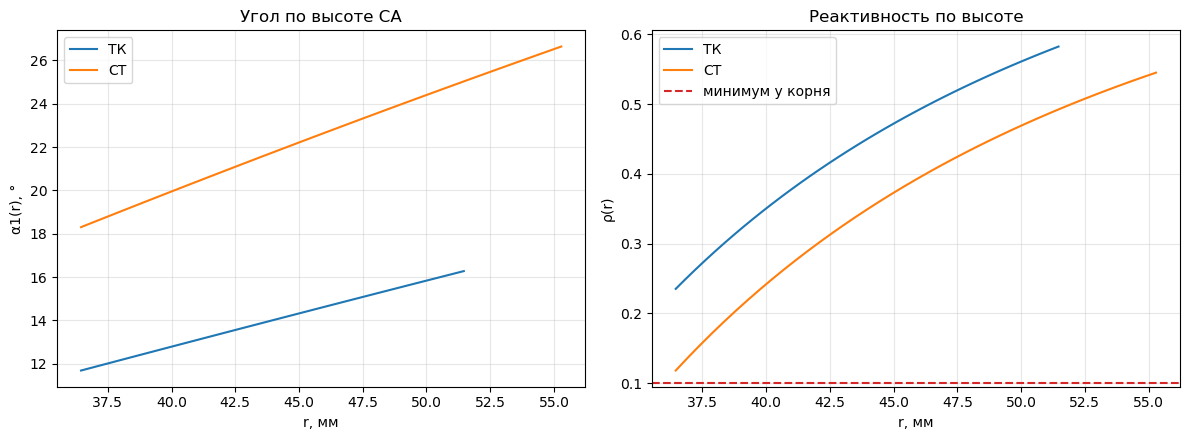

In [24]:
def radial_profile_gamma_const(r, npts=41):
    rm = r['D1']/2
    rh = r['D_hub']/2
    rt_tip = rh + r['l1']
    radius = np.linspace(rh, rt_tip, npts)
    c1u = r['c1u']*rm/radius
    c1a = np.full_like(radius, r['c1a'])
    alpha1 = np.degrees(np.arctan2(c1a, c1u))
    exponent = (r['c1u']**2*rm**2)/(2*R*r['T1'])*(1/rm**2-1/radius**2)
    p1 = r['p1']*np.exp(exponent)
    T1_ad = r['T0']*(p1/r['p0'])**((r['k']-1)/r['k'])
    rho = r['cp']*T1_ad/r['H0']*(1-(r['p2']/p1)**((r['k']-1)/r['k']))
    return pd.DataFrame({'r, мм': 1000*radius, 'c1u, м/с': c1u,
                         'c1a, м/с': c1a, 'α1(r), °': alpha1,
                         'p1(r), кПа': p1/1000, 'ρ(r)': rho})


radial_profiles = {'ТК': radial_profile_gamma_const(rt), 'СТ': radial_profile_gamma_const(rs)}
radial_summary = []
for name, df in radial_profiles.items():
    radial_summary.append({'Турбина': name,
                           'ρ корень': df['ρ(r)'].iloc[0],
                           'ρ среднее': df['ρ(r)'].iloc[len(df)//2],
                           'ρ периферия': df['ρ(r)'].iloc[-1],
                           'α1 корень, °': df['α1(r), °'].iloc[0],
                           'α1 среднее, °': df['α1(r), °'].iloc[len(df)//2],
                           'α1 периферия, °': df['α1(r), °'].iloc[-1]})
display(pd.DataFrame(radial_summary).set_index('Турбина').round(5))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for name, df in radial_profiles.items():
    axs[0].plot(df['r, мм'], df['α1(r), °'], label=name)
    axs[1].plot(df['r, мм'], df['ρ(r)'], label=name)
axs[0].set(xlabel='r, мм', ylabel='α1(r), °', title='Угол по высоте СА')
axs[1].set(xlabel='r, мм', ylabel='ρ(r)', title='Реактивность по высоте')
axs[1].axhline(LIMITS['rho_root_min'], color='tab:red', ls='--', label='минимум у корня')
for ax in axs:
    ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

## Чувствительность к потерям и радиальному зазору

Для каждого сценария выполняется повторный расчёт **того же заданного варианта**, но новый поиск геометрии не запускается. После таблицы исходные коэффициенты автоматически восстанавливаются.

In [25]:
RUN_SENSITIVITY = False

def sensitivity_study(active_design):
    base = COEF.copy()
    scenarios = [
        ('База', {}),
        ('φ СА − 0,01', {'phi': base['phi']-0.01}),
        ('ψ РК − 0,01', {'psi': base['psi']-0.01}),
        ('Зазор 0,5 мм', {'delta_mm': 0.5}),
    ]
    rows = []
    try:
        for name, changes in scenarios:
            COEF.clear(); COEF.update(base); COEF.update(changes)
            try:
                _, rtk, rst, _, hard, desired = couple_curve_design(
                    copy.deepcopy(active_design), G0=rt['G'], n_iter=14,
                    tol=2e-7, update_cycle=False)
                rows.append({'Сценарий': name, 'φ': COEF['phi'], 'ψ': COEF['psi'],
                             'δ, мм': COEF['delta_mm'], 'n ТК': rtk['n'], 'n СТ': rst['n'],
                             'ηл ТК': rtk['eta_l'], 'ηл СТ': rst['eta_l'],
                             'σ ТК, МПа': rtk['sigma'], 'σ СТ, МПа': rst['sigma'],
                             'c2 СТ, м/с': rst['c2'],
                             'Все строгие условия': all(hard.values())})
            except Exception as error:
                rows.append({'Сценарий': name, 'Ошибка': type(error).__name__,
                             'Все строгие условия': False})
    finally:
        COEF.clear(); COEF.update(base)
    return pd.DataFrame(rows).set_index('Сценарий')


ACTIVE_DESIGN = DESIGN if 'DESIGN' in globals() else MANUAL_DESIGN
if RUN_SENSITIVITY:
    sensitivity_df = sensitivity_study(ACTIVE_DESIGN)
    display(sensitivity_df.round(5))
else:
    print('Чувствительность отключена: RUN_SENSITIVITY = False')

Чувствительность отключена: RUN_SENSITIVITY = False


## Выбор количества лопаток силовой турбины

Высоты и диаметры получены из газодинамики и неразрывности. Предварительный подбор решёток выполнен по разделу 8 методички (с. 82–83), для неохлаждаемых профилей. Осевые хорды заданы через l/b_ax = 2,25 для СА и 2,75 для РК.

Угол установки: γ = 70 − 0,127(β1 − β2) − 0,0041(β1 − β2)²; хорда b = b_ax/sin(γ). Для СА используются входной угол 90° и выходной α1, для РК — β1 и β2.

Оптимальный относительный шаг вычисляется по формуле методички с K = 0,45/0,60 и c_max/b = 0,13/0,11 для СА/РК. Затем Z_расч = πD/(b·(t/b)_опт). Принимаем близкие взаимно простые числа: СА ТК — 29, РК ТК — 46, СА СТ — 31, РК СТ — 39. Фактический шаг пересчитывается по целому Z.

Число лопаток СТ задаётся вручную переменными Z_ST_CA и Z_ST_RK. Оно едино по всей высоте каждого венца: при выбранном Z локальный шаг равен 2πr/Z. Ниже показаны расчёт на среднем диаметре, принятое Z и отклонение фактического относительного шага от оптимального.

Это предварительная геометрия: после построения профилей необходимо проверить горловину и диффузорность каналов. Принятое M = 1,104 у корня СА не меняет кинематическую связь шага и числа лопаток; оптимальный шаг остаётся предварительной оценкой.

In [26]:
# Принятые целые числа лопаток силовой турбины — менять здесь.
Z_ST_CA = 31
Z_ST_RK = 39

DRAW = {
    'Z': {'ТК': {'СА': 29, 'РК': 46}, 'СТ': {'СА': Z_ST_CA, 'РК': Z_ST_RK}},
    'K_CA': 0.45, 'K_RK': 0.60,
    'cmax_over_b_CA': 0.13, 'cmax_over_b_RK': 0.11,  # неохлаждаемые профили
}

def drawing_schedule(rt, rs, draw=DRAW):
    rows = []
    previous_z = None
    for turbine, r in (('ТК', rt), ('СТ', rs)):
        for crown, l, Dm, bax in (
            ('СА', r['l1'], r['D1'], r['b_c']),
            ('РК', r['l2'], r['D2'], r['b_l']),
        ):
            crown_key = {'СА': 'CA', 'РК': 'RK'}[crown]
            inlet_angle, outlet_angle = (90.0, r['alpha1']) if crown == 'СА' else (r['beta1'], r['beta2'])
            angle_difference = inlet_angle-outlet_angle
            gamma = 70-0.127*angle_difference-0.0041*angle_difference**2
            if not 0 < gamma < 90:
                raise ValueError(f'{crown} {turbine}: недопустимый угол установки {gamma}')
            profile_chord = bax/np.sin(np.radians(gamma))
            denominator = (180-inlet_angle-outlet_angle)*np.sin(np.radians(outlet_angle))
            if denominator <= 0:
                raise ValueError(f'{crown} {turbine}: формула оптимального шага неприменима')
            tb = draw['K_'+crown_key]*(180*np.sin(np.radians(inlet_angle))/denominator)**(1/3)*(1-draw['cmax_over_b_'+crown_key])
            z_cont = np.pi*Dm/(tb*profile_chord)
            z = draw['Z'][turbine][crown]
            if isinstance(z, bool) or not isinstance(z, (int, np.integer)) or z < 3:
                raise ValueError('Z должно быть целым числом не менее 3')
            if previous_z is not None and math.gcd(z, previous_z) != 1:
                raise ValueError('Числа лопаток соседних венцов должны быть взаимно простыми')
            pitch = np.pi*Dm/z
            previous_z = z
            rows.append({'Венец': f'{crown} {turbine}',
                         'Dвт, мм [расчёт]': 1000*r['D_hub'],
                         'Dср, мм [расчёт]': 1000*Dm,
                         'Dнар, мм [расчёт]': 1000*(r['D_hub']+2*l),
                         'l, мм [расчёт]': 1000*l,
                         'b_ax, мм [предварительно]': 1000*bax,
                         'b, мм [эскиз]': 1000*profile_chord,
                         't оптимальный, мм': 1000*tb*profile_chord,
                         'шаг, мм [эскиз]': 1000*pitch,
                         'Z расчётное': z_cont, 'Z принятое': z,
                         '(t/b) оптимальное': tb, 't/b [эскиз]': pitch/profile_chord,
                         'отклонение t/b, %': 100*(pitch/profile_chord/tb-1),
                         'γ установки, ° [эскиз]': gamma})
    return pd.DataFrame(rows).set_index('Венец')


drawing_df = drawing_schedule(rt, rs)
st_blade_count_df = drawing_df.loc[['СА СТ', 'РК СТ'], [
    'Dср, мм [расчёт]', 'b_ax, мм [предварительно]', 'b, мм [эскиз]',
    'γ установки, ° [эскиз]', '(t/b) оптимальное', 't оптимальный, мм',
    'Z расчётное', 'Z принятое', 'шаг, мм [эскиз]', 't/b [эскиз]', 'отклонение t/b, %',
]]
display(st_blade_count_df.round(3))
print('Предварительный подбор по методичке, раздел 8, с. 81–83; профили неохлаждаемые.')
blade_counts = drawing_df['Z принятое'].astype(int).tolist()
assert all(math.gcd(a, b) == 1 for a, b in zip(blade_counts, blade_counts[1:]))
print(f'СТ: СА — {Z_ST_CA} лопаток, РК — {Z_ST_RK} лопаток; НОД = {math.gcd(Z_ST_CA, Z_ST_RK)}.')
print('Также проверена соседняя пара РК ТК / СА СТ. Полная геометрия четырёх венцов доступна в drawing_df.')

,"Dср, мм [расчёт]","b_ax, мм [предварительно]","b, мм [эскиз]","γ установки, ° [эскиз]",(t/b) оптимальное,"t оптимальный, мм",Z расчётное,Z принятое,"шаг, мм [эскиз]",t/b [эскиз],"отклонение t/b, %"
Венец,,,,,,,,,,,
СА СТ,91.7380,8.3730,12.3190,42.8150,0.7470,9.2040,31.3140,31,9.2970,0.7550,1.0120
РК СТ,93.7100,7.5670,8.8640,58.6130,0.8600,7.6270,38.6000,39,7.5490,0.8520,-1.0250


Предварительный подбор по методичке, раздел 8, с. 81–83; профили неохлаждаемые.
СТ: СА — 31 лопаток, РК — 39 лопаток; НОД = 1.
Также проверена соседняя пара РК ТК / СА СТ. Полная геометрия четырёх венцов доступна в drawing_df.


## 19. Силовая турбина: треугольники после СА и после РК в трёх сечениях

Для предварительного профилирования рассматриваются корневое, среднее и периферийное сечения. Принимается закон постоянной циркуляции

$$r_1c_{1u}=\mathrm{const},\qquad r_2c_{2u}=\mathrm{const},$$

а осевые составляющие $c_{1a}$ и $c_{2a}$ считаются постоянными по высоте. Тогда локальная работа Эйлера $L_u=u_1c_{1u}+u_2c_{2u}$ одинакова во всех сечениях. Радиусы на входе и выходе РК определяются отдельно, поскольку высоты $l_1$ и $l_2$ различаются.

Силовая турбина: 1 — после СА (вход РК), 2 — после РК.
На каждом графике c = w + u; c2u в таблице отсчитывается против вращения.


,h/l,"r1, мм","r2, мм","u1, м/с","u2, м/с","c1u, м/с","c1a, м/с","c1, м/с","w1, м/с","c2u, м/с","c2a, м/с","c2, м/с","w2, м/с","α1, °","β1, °","α2, °","β2, °",ρ,M(c1),M(w1),M(c2),M(w2),"Lu, Дж/кг",невязка Euler
Сечение,,,,,,,,,,,,,,,,,,,,,,,,
Корень,0.0000,36.4500,36.4500,323.1349,323.1349,608.3681,201.2370,640.7870,349.0764,0.0000,236.6325,236.6325,400.5135,18.3033,35.2036,90.0000,36.2154,0.1181,1.1043,0.6016,0.4116,0.6967,196584.9307,-0.0000
Среднее,0.5000,45.8691,46.8548,406.6370,415.3753,483.4408,201.2370,523.6519,215.3953,0.0000,236.6325,236.6325,478.0497,22.6000,69.1102,90.0000,29.6695,0.3919,0.8741,0.3596,0.4116,0.8316,196584.9307,-0.0000
Периферия,1.0000,55.2883,57.2597,490.1392,507.6157,401.0798,201.2370,448.7330,220.0634,0.0000,236.6325,236.6325,560.0612,26.6447,113.8723,90.0000,24.9933,0.5452,0.7370,0.3614,0.4116,0.9742,196584.9307,-0.0000


,max |невязка Euler|,"α1 у корня, °",α1 корня ≥ 13°,max M,все M < 1
Турбина,,,,,
СТ,0.0000,18.3033,True,1.1043,False
ТК,0.0000,11.6811,False,1.0209,False


Есть локальные M ≥ 1. Перед профилированием уточнить закон закрутки или исходный вариант.
α1 у корня ниже 13°. Методичка допускает 11–12° для маломощных турбин, но такой выбор требует обоснования.


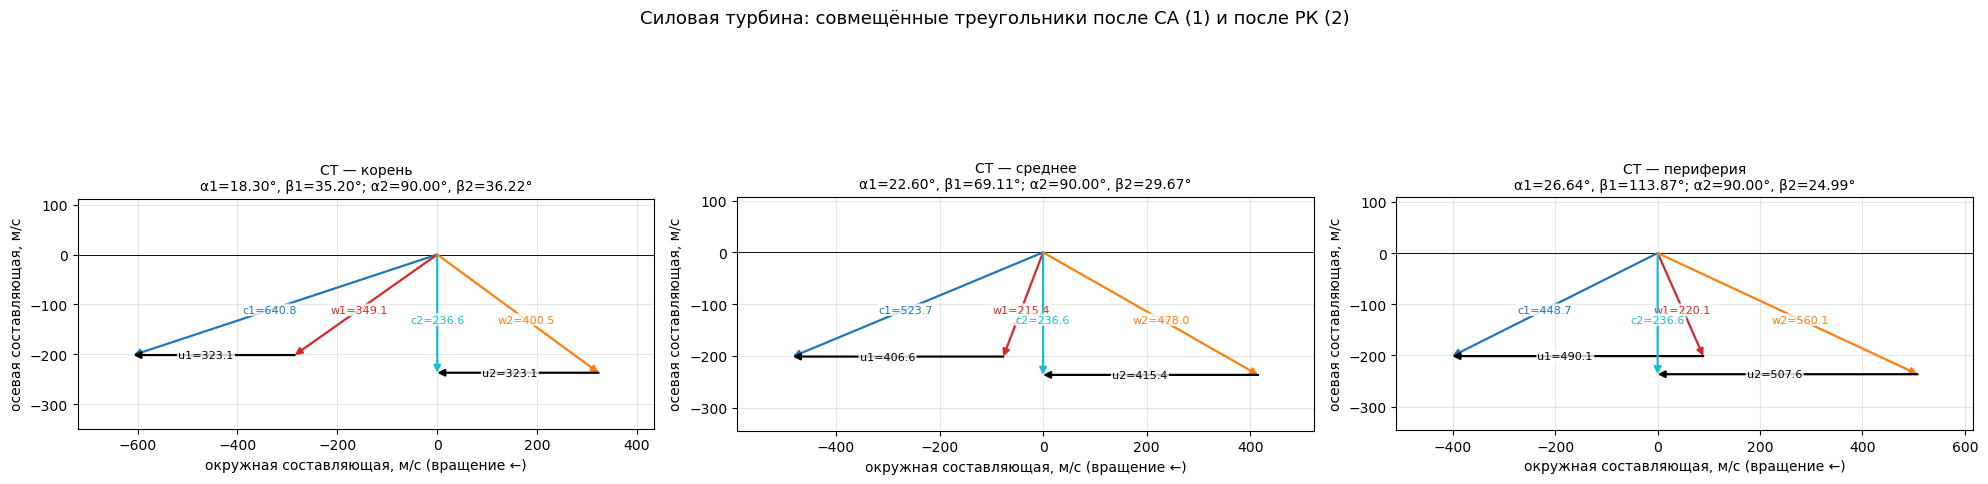

In [27]:
SECTION_LEVELS = (('Корень', 0.0), ('Среднее', 0.5), ('Периферия', 1.0))

def velocity_triangles_three_sections(r, turbine):
    rows = []
    r_hub = r['D_hub'] / 2
    r1_mid, r2_mid = r['D1'] / 2, r['D2'] / 2
    omega = 2 * np.pi * r['n'] / 60
    T2_total_local = r['T2'] + r['c2']**2 / (2*r['cp'])
    for section, height_fraction in SECTION_LEVELS:
        r1 = r_hub + height_fraction * r['l1']
        r2 = r_hub + height_fraction * r['l2']
        c1u = r['c1u'] * r1_mid / r1
        c2u = r['c2u'] * r2_mid / r2
        c1a, c2a = r['c1a'], r['c2a']
        u1, u2 = omega*r1, omega*r2
        w1u, w2u = c1u-u1, -(c2u+u2)
        c1, w1 = np.hypot(c1u, c1a), np.hypot(w1u, c1a)
        c2, w2 = np.hypot(c2u, c2a), np.hypot(w2u, c2a)
        alpha1 = np.degrees(np.arctan2(c1a, c1u))
        beta1 = np.degrees(np.arctan2(c1a, w1u))
        alpha2 = np.degrees(np.arctan2(c2a, c2u))
        beta2 = np.degrees(np.arctan2(c2a, c2u+u2))
        Lu = u1*c1u + u2*c2u
        exponent = (r['c1u']**2*r1_mid**2)/(2*R*r['T1']) * (1/r1_mid**2-1/r1**2)
        p1 = r['p1'] * np.exp(exponent)
        T1_ad = r['T0'] * (p1/r['p0'])**((r['k']-1)/r['k'])
        rho = r['cp']*T1_ad/r['H0'] * (1-(r['p2']/p1)**((r['k']-1)/r['k']))
        T1_local = r['T0'] - c1**2/(2*r['cp'])
        T2_local = T2_total_local - c2**2/(2*r['cp'])
        a1 = np.sqrt(r['k']*R*T1_local)
        a2 = np.sqrt(r['k']*R*T2_local)
        rows.append({
            'Турбина': turbine, 'Сечение': section, 'h/l': height_fraction,
            'r1_mm': 1000*r1, 'r2_mm': 1000*r2,
            'u1': u1, 'u2': u2, 'c1u': c1u, 'c1a': c1a, 'c1': c1, 'w1': w1,
            'c2u': c2u, 'c2a': c2a, 'c2': c2, 'w2': w2,
            'alpha1': alpha1, 'beta1': beta1, 'alpha2': alpha2, 'beta2': beta2,
            'rho': rho, 'M_c1': c1/a1, 'M_w1': w1/a1, 'M_c2': c2/a2, 'M_w2': w2/a2,
            'Lu': Lu, 'Euler_error': (Lu-r['Lu'])/r['Lu'],
        })
    return pd.DataFrame(rows).set_index(['Турбина', 'Сечение'])


def plot_section_triangle(ax, row, title, station):
    # На чертеже вращение направлено влево, осевой поток — вниз.
    # Зеркально отражаем окружные компоненты всех векторов; расчётные углы неизменны.
    origin = np.zeros(2)
    if station not in (1, 2):
        raise ValueError('station: 1 — после СА, 2 — после РК')
    j = str(station)
    cu = row['c1u'] if station == 1 else -row['c2u']
    c = np.array([-cu, -row['c'+j+'a']])
    u = np.array([-row['u'+j], 0.0])
    w = c-u
    assert np.allclose(c, w+u)

    def arrow(vector, start, color, linestyle, label):
        ax.annotate('', xy=start+vector, xytext=start,
                    arrowprops=dict(arrowstyle='-|>', color=color, lw=1.6, ls=linestyle,
                                    shrinkA=0, shrinkB=0))
        middle = start + 0.55*vector
        ax.text(middle[0], middle[1], label, color=color, fontsize=8, ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none', alpha=0.8))

    arrow(c, origin, 'tab:blue' if station == 1 else 'tab:cyan', '-', f"c{j}={row['c'+j]:.1f}")
    arrow(w, origin, 'tab:red' if station == 1 else 'tab:orange', '-', f"w{j}={row['w'+j]:.1f}")
    arrow(u, w, 'black', '-', f"u{j}={row['u'+j]:.1f}")
    points = np.array([origin, c, w])
    pad = max(25.0, 0.08*np.ptp(points, axis=0).max())
    ax.set_xlim(points[:, 0].min()-pad, points[:, 0].max()+pad)
    ax.set_ylim(points[:, 1].min()-pad, points[:, 1].max()+pad)
    ax.axhline(0, color='black', lw=0.5)
    ax.set_aspect('equal'); ax.grid(alpha=0.3)
    ax.set_xlabel('окружная составляющая, м/с (вращение ←)')
    ax.set_ylabel('осевая составляющая, м/с')
    ax.set_title(f"{title}\nr{j}={row['r'+j+'_mm']:.2f} мм; "
                 f"α{j}={row['alpha'+j]:.2f}°, β{j}={row['beta'+j]:.2f}°", fontsize=10)


if coupled_ok:
    triangle_sections = pd.concat([
        velocity_triangles_three_sections(rt, 'ТК'),
        velocity_triangles_three_sections(rs, 'СТ'),
    ])
    triangle_table = triangle_sections.rename(columns={
        'r1_mm': 'r1, мм', 'r2_mm': 'r2, мм', 'u1': 'u1, м/с', 'u2': 'u2, м/с',
        'c1u': 'c1u, м/с', 'c1a': 'c1a, м/с', 'c1': 'c1, м/с', 'w1': 'w1, м/с',
        'c2u': 'c2u, м/с', 'c2a': 'c2a, м/с', 'c2': 'c2, м/с', 'w2': 'w2, м/с',
        'alpha1': 'α1, °', 'beta1': 'β1, °', 'alpha2': 'α2, °', 'beta2': 'β2, °',
        'rho': 'ρ', 'M_c1': 'M(c1)', 'M_w1': 'M(w1)', 'M_c2': 'M(c2)', 'M_w2': 'M(w2)',
        'Lu': 'Lu, Дж/кг', 'Euler_error': 'невязка Euler',
    })
    print('Силовая турбина: 1 — после СА (вход РК), 2 — после РК.')
    print('На каждом графике c = w + u; c2u в таблице отсчитывается против вращения.')
    display(triangle_table.xs('СТ', level='Турбина').round(4))

    section_checks = pd.DataFrame({
        'max |невязка Euler|': triangle_sections.groupby(level=0)['Euler_error'].apply(lambda x: x.abs().max()),
        'α1 у корня, °': triangle_sections.xs('Корень', level='Сечение')['alpha1'],
        'α1 корня ≥ 13°': triangle_sections.xs('Корень', level='Сечение')['alpha1'] >= 13.0,
        'max M': triangle_sections[['M_c1', 'M_w1', 'M_c2', 'M_w2']].max(axis=1).groupby(level=0).max(),
        'все M < 1': triangle_sections[['M_c1', 'M_w1', 'M_c2', 'M_w2']].max(axis=1).groupby(level=0).max() < 1.0,
    })
    display(section_checks.round(5))
    assert triangle_sections['Euler_error'].abs().max() < 1e-12
    for turbine, result in (('ТК', rt), ('СТ', rs)):
        for key in ('u1', 'u2', 'c1', 'c2', 'w1', 'w2', 'alpha1', 'alpha2', 'beta1', 'beta2'):
            assert np.isclose(triangle_sections.loc[(turbine, 'Среднее'), key], result[key], rtol=1e-10)
    if not section_checks['все M < 1'].all():
        print('Есть локальные M ≥ 1. Перед профилированием уточнить закон закрутки или исходный вариант.')
    if not section_checks['α1 корня ≥ 13°'].all():
        print('α1 у корня ниже 13°. Методичка допускает 11–12° для маломощных турбин, но такой выбор требует обоснования.')

    # Совмещённые треугольники: общая вершина абсолютных и относительных скоростей.
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    for column_index, (section, _) in enumerate(SECTION_LEVELS):
        ax = axs[column_index]
        row = triangle_sections.loc[('СТ', section)]
        for station in (1, 2):
            plot_section_triangle(ax, row, section, station)
        points = np.array([[0.0, 0.0],
                           [-row['c1u'], -row['c1a']],
                           [row['u1']-row['c1u'], -row['c1a']],
                           [row['c2u'], -row['c2a']],
                           [row['c2u']+row['u2'], -row['c2a']]])
        pad = max(35.0, 0.12*np.ptp(points, axis=0).max())
        ax.set_xlim(points[:, 0].min()-pad, points[:, 0].max()+pad)
        ax.set_ylim(points[:, 1].min()-pad, pad)
        ax.set_title(f"СТ — {section.lower()}\n"
                     f"α1={row['alpha1']:.2f}°, β1={row['beta1']:.2f}°; "
                     f"α2={row['alpha2']:.2f}°, β2={row['beta2']:.2f}°", fontsize=10)
    fig.suptitle('Силовая турбина: совмещённые треугольники после СА (1) и после РК (2)', fontsize=13)
    plt.tight_layout(); plt.show()
else:
    print('Вариант не рассчитан — треугольники не строятся.')

## 20. Меридиональное сечение проточной части

Длина переходного канала от выхода РК ТК до входа СА СТ вычисляется по наружному контуру при постоянной втулке и угле стенки к оси 12°.

D_вх = D_вт + 2l₂_ТК + 2δ; D_вых = D_вт + 2l₁_СТ; L = (D_вых − D_вх)/(2 tan 12°). Радиальный зазор δ учитывается над РК ТК; СА СТ примыкает к корпусу без зазора. L является полным расстоянием между венцами, поэтому осевой зазор за РК к нему не прибавляется.

На схеме наружный контур над РК проходит с радиальным зазором. Хорды и остальные осевые размеры остаются предварительными.


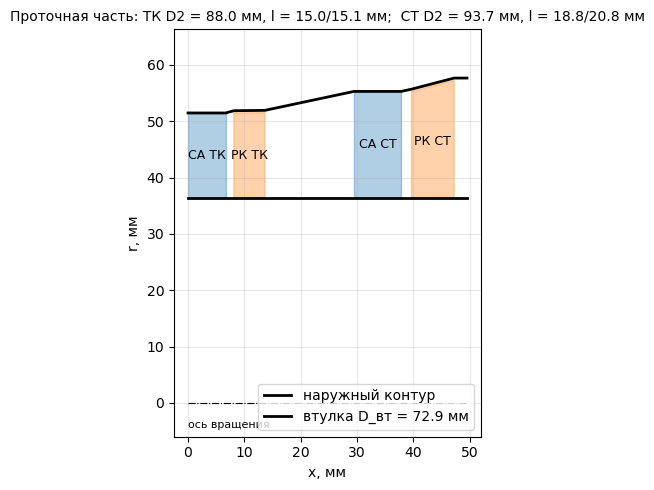

In [28]:
def plot_meridional(rt, rs):
    duct = transition_geometry(rt, rs)
    clearance_mm = COEF['delta_mm']
    rh = rt['D_hub'] / 2 * 1e3
    x, tip, blades = 0.0, [], []
    for r, nm in ((rt, 'ТК'), (rs, 'СТ')):
        l1, l2 = r['l1'] * 1e3, r['l2'] * 1e3
        bc, bl, sc, sl = r['b_c'] * 1e3, r['b_l'] * 1e3, r['s_c'] * 1e3, r['s_l'] * 1e3
        tip += [(x, rh + l1), (x + bc, rh + l1)]
        blades.append(('СА ' + nm, [(x, rh), (x + bc, rh), (x + bc, rh + l1), (x, rh + l1)], 'tab:blue'))
        x += bc + sc
        tip += [(x, rh + l1 + clearance_mm), (x + bl, rh + l2 + clearance_mm)]
        blades.append(('РК ' + nm, [(x, rh), (x + bl, rh), (x + bl, rh + l2), (x, rh + l1)], 'tab:orange'))
        x += bl
        if nm == 'ТК':
            # L — полное расстояние между венцами: sl повторно не прибавляется.
            x += 1000*duct['length']
        else:
            x += sl
            tip.append((x, rh + l2 + clearance_mm))
    fig, ax = plt.subplots(figsize=(14, 5))
    tx, ty = zip(*tip)
    ax.plot(tx, ty, 'k-', lw=2, label='наружный контур')
    ax.plot([0, x], [rh, rh], 'k-', lw=2, label=f'втулка D_вт = {2*rh:.1f} мм')
    for label, poly, col in blades:
        px, py = zip(*poly)
        ax.fill(px, py, color=col, alpha=0.35, ec=col)
        ax.text(np.mean(px), np.mean(py), label, ha='center', va='center', fontsize=9)
    ax.plot([0, x], [0, 0], 'k-.', lw=0.8)
    ax.text(0, -3, 'ось вращения', fontsize=8, va='top')
    ax.set_aspect('equal')
    ax.set_ylim(-6, max(ty) * 1.15)
    ax.set_xlabel('x, мм'); ax.set_ylabel('r, мм')
    ax.grid(alpha=0.3)
    ax.legend(loc='lower right')
    ax.set_title(f"Проточная часть: ТК D2 = {rt['D2']*1e3:.1f} мм, l = {rt['l1']*1e3:.1f}/{rt['l2']*1e3:.1f} мм;  "
                 f"СТ D2 = {rs['D2']*1e3:.1f} мм, l = {rs['l1']*1e3:.1f}/{rs['l2']*1e3:.1f} мм", fontsize=10)
    plt.tight_layout(); plt.show()


if coupled_ok:
    plot_meridional(rt, rs)
else:
    print('Вариант не рассчитан — проточная часть не строится.')